# LSST Y1 × DESI: where model A breaks, and models A and B against $k_\mathrm{max}$

The forecast fits the DESI band powers $C_\ell^{gg}$ of thin redshift bins,
computed without the Limber approximation, on four bin layouts: bins of equal
comoving width $\Delta d_\mathrm{com} = 62$ Mpc, and bins of fixed redshift
width $\Delta z = 0.02$, $0.05$ and $0.2$. `EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb`
(the model A notebook) forecasts with the one-loop bias model A of
`notes/higher_order_bias` at one scale cut. This notebook scans the cut for
four results:

1. the $k_\mathrm{max}$ at which each model breaks, under truths it does not
   model or models with a prior (section 7);
2. the figures of merit of models A and B against $k_\mathrm{max}$ (section 6);
3. the data of the correlated-prior note's figure of the FoM against
   $k_\mathrm{max}$ (section 8);
4. the summary model, model B + tilts on the pessimistic linear-bias prior:
   its FoMs, shifts and error-bar test at every cut, and the data of the
   summary note's figures (section 9).

**Symbols.** $D(z)$ is the linear growth factor with $D(0) = 1$;
$w(a) = w_0 + w_a(1 - a)$ the dark-energy equation of state, with $a$ the scale
factor; $\Omega_m$ the matter density today in units of the critical density;
$A_s$ the amplitude of the primordial curvature power spectrum, sampled as
`As_1e9` $= 10^9 A_s$. ${\rm FoM}(w_0, w_a) = [\det \mathrm{Cov}(w_0, w_a)]^{-1/2}$
is the inverse area of the marginalized $(w_0, w_a)$ error ellipse, and
${\rm FoM}(\Omega_m, 10^9 A_s)$ the same for $(\Omega_m, 10^9 A_s)$. $\sigma$ is
a parameter's marginalized one-sigma error.

**Model A** (as in the model A notebook). The linear bias $b_{1,i}$ of bin $i$
is free per bin under a linear-bias prior. The quadratic bias $b_2$ and the
tidal bias $b_{s^2}$ follow it through calibrations plus one offset per tracer
group $g$: $b_{2,i} = b_2^\mathrm{L}(b_{1,i}) + \Delta_{2,g}$, with
$b_2^\mathrm{L}$ the Lazeyras et al. fit (arXiv:1511.01096), and
$b_{s^2,i} = -\tfrac{4}{7}(b_{1,i} - 1) + \Delta_{s,g}$ (co-evolution). Each group
also carries a $k^2$ counterterm $\alpha_0$, in $h^{-2}\,\mathrm{Mpc}^2$, a
white noise $\mathrm{SN}_0$ beyond Poisson, in units of the bin's Poisson power
$1/\bar n_i$ ($\bar n_i$ the tracer density), and the stochastic term
$\mathrm{SN}_2\,k^2\mu^2$, with $\mu$ the cosine of the angle to the line of
sight, in units of $f_\mathrm{sat}\sigma_\mathrm{sat}^2/\bar n_i$: $f_\mathrm{sat}$ the
satellite fraction and $\sigma_\mathrm{sat}$ the satellites' velocity dispersion
in distance units (DESI DR1 values per sample, `SN2_UNIT` of
`likelihood/desi_cl.py`; not the Fingers-of-God dispersion $\sigma_v$ that
smooths the bins' redshift distributions). $\mathrm{SN}_2$ projects through the
radial derivatives of the bin kernels, so adjacent bins, which share an edge,
get an anticorrelated cross term that $\mathrm{SN}_0$ cannot mimic.

**Model B** keeps that linear sector and the two stochastic terms, widens the
two offsets and adds the radial counterterm $\alpha_2$ per group, in the DESI
DR1 convention: the counterterm density is
$\tfrac{1}{2}(b_1\alpha_0 + f\mu^2\alpha_2)\,k^2\delta_\mathrm{L}$, with $f$ the
linear growth rate and $\delta_\mathrm{L}$ the linear density contrast.

Model B here carries no redshift-space one-loop terms; CosmoLike has none. The
Gaussian priors are centered on zero:

| parameter | model A | model B |
|---|---|---|
| $\Delta_2$ | 1.0 | 2.0 |
| $\Delta_s$ | 0.5 | 1.0 |
| $\alpha_0$ [$h^{-2}\,\mathrm{Mpc}^2$] | $0.5/k_\mathrm{max}^2$ | $0.5/k_\mathrm{max}^2$ |
| $\alpha_2$ [$h^{-2}\,\mathrm{Mpc}^2$] | none | $0.5/k_\mathrm{max}^2$ |
| $\mathrm{SN}_0$ [$1/\bar n_i$] | 2 | 2 |
| $\mathrm{SN}_2$ [$f_\mathrm{sat}\sigma_\mathrm{sat}^2/\bar n_i$] | 5 | 5 |

The counterterm widths are the DESI rule of a 50% correction at the cut,
evaluated at every cut: $88.9\,h^{-2}\,\mathrm{Mpc}^2$ at
$k_\mathrm{max} = 0.075\,h/\mathrm{Mpc}$, DESI's $12.5$ at $0.2$.

**Variants.** Each model comes in two variants: model A (or B) has one offset,
counterterm and stochastic amplitude per group, and model A + tilts (or
B + tilts) also tilts $\Delta_2$, $\Delta_s$, $\alpha_0$ and, in model B,
$\alpha_2$ linearly in redshift across the group, with flat priors on the
tilts. $\mathrm{SN}_0$ and $\mathrm{SN}_2$ never tilt: their Poisson part is
known bin by bin. The code labels are `'A'`, `'A tilts'`, `'B'` and
`'B tilts'`. The linear-bias priors keep their own names (baseline,
pessimistic, free).

**Linear-bias priors.** The fits use three of the four priors of the
correlated-prior note, `notes/correlated_bias_prior_v2`: baseline, pessimistic
and free (code label `'independent'`). The growth-tied prior is omitted: it
fails that note's accuracy test, so its FoM means nothing.

**The scale cut.** Bin $i$ is cut at $k_\mathrm{max}/D(\bar z_i)$, with
$\bar z_i$ its mean redshift, by the non-Limber ultraviolet-fraction criterion
(arXiv:2603.13031): a band is kept while less than $\alpha = 0.05$ of it comes
from the power spectrum above that wavenumber, within the shipped mask. Every
$k_\mathrm{max}$ here is quoted at $z = 0$.

**Inputs and outputs.** The notebook reads, never writes, the model A
notebook's derivative caches and the linear notebook's scale cuts. It computes
the two model B templates once and caches them in `chains/`. It writes the
data of one figure folder of the correlated-prior note and of four figure
folders of the summary note, `notes/bias_model_summary`.

## 1. Set up Python and the Fisher module

Imports and the paths to CosmoLike and to the project's interface. The
project's Fisher module, imported as `fm`, builds the model A likelihood in
section 4, where the model B templates are computed.

In [1]:
import importlib
import inspect
import json
import os
import pickle
import subprocess
import sys
import time
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is
# set before the Fisher module imports the compiled interface.
os.environ['OMP_NUM_THREADS'] = '8'
import numpy as np
import pandas as pd
import scipy.integrate
import scipy.linalg
import scipy.special
from IPython.display import Image, display

# start_cocoa.sh exports ROOTDIR, the Cocoa/ folder; the EXAMPLE yamls name
# their data and codes relative to it
ROOTDIR = os.environ['ROOTDIR']
os.chdir(ROOTDIR)

sys.path.insert(0, ROOTDIR + '/external_modules/code/cosmolike_core')
sys.path.insert(0, ROOTDIR + '/projects/lssty1xdesi/interface')
import cosmolike_lssty1xdesi_fisher as fm
print('Using the Fisher module at %s' % fm.__file__)
pd.set_option('display.float_format', '{:.4g}'.format)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 220)
# print every row of the long tables (pandas elides rows beyond 60)
pd.set_option('display.max_rows', 200)

Using the Fisher module at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lssty1xdesi/interface/cosmolike_lssty1xdesi_fisher.py


## 2. The settings

- `COSMO`: the seven cosmological parameters ($10^9 A_s$, $n_s$, $H_0$,
  $\Omega_b$, $\Omega_m$, $w_0$, $w_a$), all with flat priors.
- `INVCOV_SCALE`: the DESI covariance is computed for 14,000 deg$^2$; its
  inverse is rescaled to the survey's 12,300 deg$^2$.
- `SCALE_CUTS_CACHE`: the linear notebook's ultraviolet-fraction cuts,
  `KMAX_CUTS` $= 0.05, 0.075, \ldots, 0.2\,h/\mathrm{Mpc}$ at $z = 0$ (`KMAX_MAX`;
  the cache's larger cuts are not used).
- `LAYOUTS`: the four layouts on their model A example yamls, with the settings
  of the model A notebook. `MODEL_A_CACHE` and `MODEL_A_STEPS`: the model A
  derivative caches and the steps they were computed with; a cache made with
  other settings is refused.
- `FIXED_WIDTHS` and `COUNTERTERM_FRACTION`: the prior widths of the table
  above; `prior_widths` returns them at one cut.
- `ALPHA2_SETTER`, `ALPHA2_KEYWORD` and `A2_STEP`: the compiled interface's
  setter of the per-bin $\alpha_2$ (in $h^{-2}\,\mathrm{Mpc}^2$), its keyword,
  and the finite-difference step of section 4. `TEMPLATE_CACHE` and
  `RECOMPUTE_TEMPLATES`: the cache of the model B templates.
- `ALPHA2_TRUTH`, `SN2_TRUTH`, `CAL_DRIFT`, `SCENARIOS`, `SHIFT_THRESHOLD`,
  `MISMATCH_TRUTHS`, `RANDOM_FAMILIES`,
  `SCATTER_DRAWS`, `SCATTER_SEED` and `ONE_SIGMA`: the truths of section 7, the
  threshold of its break point, $\sigma/3$, and the content of a $1\sigma$
  region, 68.3%.
- `LSST_Y1_SRD_FOM` $= 17.26$ and `LSST_Y1_SRD_FOM_OM_AS` $= 214.9$: the LSST Y1
  3x2pt references of the `lsst_y1` project, FoM$(w_0, w_a)$ and
  FoM$(\Omega_m, 10^9 A_s)$ from one Fisher matrix.
- `NOTE_PLOTS`: the correlated-prior note's plots folder, where section 8
  writes; `MODEL_A_LADDER`: the model A notebook's FoMs, which section 6 checks
  against.

In [2]:
PROJECT = 'projects/lssty1xdesi/'
CHAINS = ROOTDIR + '/projects/lssty1xdesi/chains/'
DESI_DATA = ROOTDIR + '/projects/lssty1xdesi/data/'
# the figures of this notebook go to the v2 note
NOTE_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/correlated_bias_prior_v2/plots/'
# the model A notebook's FoMs at its cut (the cross-check of section 6)
MODEL_A_LADDER = NOTE_PLOTS + 'baseline_ladder/data.json'
COSMO = ['As_1e9', 'ns', 'H0', 'omegab', 'omegam', 'w0', 'wa']
# one footprint for every probe [deg^2]; the DESI covariance files are built
# at DESI_COV_AREA_DEG2
AREA_DEG2 = 12300.0
DESI_COV_AREA_DEG2 = 14000.0
INVCOV_SCALE = AREA_DEG2/DESI_COV_AREA_DEG2
H_MAIN = 0.02
# the UV-fraction cuts of the linear notebook: every k_max [h/Mpc at z = 0]
# with its kept bands per layout
SCALE_CUTS_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_SCALE_CUTS.pkl'
# LSST Y1 3x2pt in real space, the SRD setup (lsst_y1 project): the FoM of
# (w0, wa) and of (Omega_m, 10^9 A_s) from the Fisher matrix of its
# EXAMPLE_EVALUATE2.ipynb (chains/EXAMPLE_EVALUATE2_FISHER_3x2pt.pkl)
LSST_Y1_SRD_FOM = 17.26
LSST_Y1_SRD_FOM_OM_AS = 214.9

# The four layouts at the model A notebook's settings (likelihood overrides
# and overall accuracy boost), on their model A example yamls. The entries
# must equal the model A notebook's: its caches store them and are refused
# when they differ.
LAYOUTS = {
    'Delta d_com = 62 Mpc': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A1.yaml',
        'dataset': 'lssty1xdesi_desi_dr3',
        'bias_params': PROJECT + 'likelihood/params_desi.yaml',
        'overrides': {}, 'accuracy_boost': 1.0},
    'Delta z = 0.02': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A2.yaml',
        'dataset': 'lssty1xdesi_desi_dr1_dz0p02',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p02.yaml',
        'overrides': {}, 'accuracy_boost': 1.0},
    'Delta z = 0.05': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A3.yaml',
        'dataset': 'lssty1xdesi_desi_dr1_dz0p05',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p05.yaml',
        'overrides': {'nonlimber_accuracyboost': 32.0}, 'accuracy_boost': 1.0},
    'Delta z = 0.2': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A4.yaml',
        'dataset': 'lssty1xdesi_desi_dr1_dz0p20',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p20.yaml',
        'overrides': {'nonlimber_accuracyboost': 64.0}, 'accuracy_boost': 3.0},
}
LAYOUT_LABELS = {'Delta d_com = 62 Mpc': r'$\Delta d_\mathrm{com} = 62$ Mpc',
                 'Delta z = 0.02': r'$\Delta z = 0.02$',
                 'Delta z = 0.05': r'$\Delta z = 0.05$',
                 'Delta z = 0.2': r'$\Delta z = 0.2$'}
# colorblind-safe layout colors (Okabe-Ito, without its green): no red or
# green in any figure
LAYOUT_COLORS = {'Delta d_com = 62 Mpc': '#0072B2', 'Delta z = 0.02': '#E69F00',
                 'Delta z = 0.05': '#CC79A7', 'Delta z = 0.2': '#56B4E9'}
# the model A notebook's derivative caches (read only) and the steps of its
# per-bin operator columns: b1 relative, b2 and bs2 absolute, alpha_0 in
# h^-2 Mpc^2
MODEL_A_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_MODEL_A_DERIVATIVES_{:d}.pkl'
MODEL_A_STEPS = {'b1': 0.01, 'b2': 0.02, 'bs2': 0.02, 'a0': 5.0}

# The Gaussian prior widths that do not depend on the cut (notes/
# higher_order_bias, its recommendation section): the b2 and bs2 offsets, and
# SN0 and SN2 in their units (Poisson power; f_sat sigma_sat^2 times it).
FIXED_WIDTHS = {
    'A': {'DB2': 1.0, 'DBS': 0.5, 'SN0': 2.0, 'SN2': 5.0},
    'B': {'DB2': 2.0, 'DBS': 1.0, 'SN0': 2.0, 'SN2': 5.0},
}
# the counterterm widths: a correction of this fraction of the linear
# spectrum at k_max, width = COUNTERTERM_FRACTION/k_max^2 [h^-2 Mpc^2]
COUNTERTERM_FRACTION = 0.5
# the per-group parameter families of each model, and the tilt that model A
# + tilts and model B + tilts add (SN0 and SN2 never tilt)
MODEL_FAMILIES = {'A': ['DB2', 'DBS', 'A0', 'SN0', 'SN2'],
                  'B': ['DB2', 'DBS', 'A0', 'A2', 'SN0', 'SN2']}
TILT_OF = {'DB2': 'TB2', 'DBS': 'TBS', 'A0': 'TA0', 'A2': 'TA2'}
VARIANTS = ['A', 'A tilts', 'B', 'B tilts']
MODEL_A_VARIANTS = ['A', 'A tilts']
# the names the printed tables and the figures give the variants
VARIANT_LABELS = {'A': 'model A', 'A tilts': 'model A + tilts', 'B': 'model B',
                  'B tilts': 'model B + tilts'}
# the linear-bias priors of the fits ('independent' is the free prior)
FIT_PRIORS = ['baseline', 'pessimistic', 'independent']
PRIOR_LABELS = {'baseline': 'baseline', 'pessimistic': 'pessimistic',
                'independent': 'free'}
BIAS_GROUP_NAMES = ['BGS', 'LRG1', 'LRG2', 'LRG3', 'ELG1', 'ELG2']
BIAS_ASSUMPTIONS = {
    'baseline': {'L': 0.2, 'sigma_b': {'BGS': 0.03, 'LRG1': 0.01, 'LRG2': 0.01,
                                       'LRG3': 0.01, 'ELG1': 0.01, 'ELG2': 0.01}},
    'pessimistic': {'L': 0.05, 'sigma_b': {name: 0.03 for name in BIAS_GROUP_NAMES}},
}


def prior_widths(model, kmax):
    '''The Gaussian prior widths of one model's per-group parameters at a cut.

    Arguments:
      model = 'A' or 'B'.
      kmax  = the cut [h/Mpc at z = 0]; it sets the counterterm widths.

    Returns:
      dict {family: width}: DB2, DBS, A0, SN0 (and A2, SN2 for model B).
    '''
    widths = dict(FIXED_WIDTHS[model])
    widths['A0'] = COUNTERTERM_FRACTION/kmax**2
    if model == 'B':
        widths['A2'] = COUNTERTERM_FRACTION/kmax**2
    return widths


# The model B templates. ALPHA2_SETTER is the compiled interface's per-bin
# alpha_2 setter, called as setter(A2=array) with alpha_2 in h^-2 Mpc^2; the
# step is central and the term is linear, so any step gives the same column.
ALPHA2_SETTER = 'set_nuisance_bias_alpha2'
ALPHA2_KEYWORD = 'A2'
A2_STEP = 5.0
TEMPLATE_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_MODEL_B_TEMPLATES_{:d}.pkl'
RECOMPUTE_TEMPLATES = False

# The bias truths of section 7, each at one sigma and the same in every bin
# (the drift: linear across each group), applied to a fit of each variant;
# each is a term the variant does not model, or models with a prior:
#   alpha_2 = +-ALPHA2_TRUTH h^-2 Mpc^2 (model A only: model B fits alpha_2);
#   SN2 = +-SN2_TRUTH units of f_sat sigma_sat^2/nbar;
#   the b2 and bs2 offsets at +-1 sigma of the variant's own widths;
#   the calibration drift: the offsets linear in redshift across each group,
#     with zero mean, changing by CAL_DRIFT from the group's first bin to its
#     last (the model A notebook's calibration drift; the tilts of model A +
#     tilts and model B + tilts absorb it). Model B gets the same drift; its alpha_0 and alpha_2
#     tilts are not exercised.
ALPHA2_TRUTH = 12.5
SN2_TRUTH = 5.0
CAL_DRIFT = {'b2': 1.0, 'bs2': 0.5}
# the two scenarios of the figure: the baseline linear-bias prior with model A
# and model B, and the pessimistic prior with model A + tilts and model B + tilts
SCENARIOS = {
    'baseline': {'prior': 'baseline', 'A': 'A', 'B': 'B'},
    'pessimistic': {'prior': 'pessimistic', 'A': 'A tilts', 'B': 'B tilts'},
}
# A diagnostic outside the break point, a prior mismatch: model A fitted to
# the offsets at model B's widths, twice model A's.
MISMATCH_TRUTHS = {
    'offsets + (2, 1)': {'b2': 2.0, 'bs2': 1.0},
    'offsets - (2, 1)': {'b2': -2.0, 'bs2': -1.0},
}
# The random truths draw alpha_2 per group from model B's prior;
# every other parameter, SN0, SN2 and the offsets included, is drawn from the
# fit's own (model A) prior.
RANDOM_FAMILIES = ['A2']
SCATTER_DRAWS = 2000
SCATTER_SEED = 20261107
SHIFT_THRESHOLD = 1.0/3.0
# the probability inside a fit's one-sigma region: the 1 sigma interval of
# one parameter, and the (w0, wa) ellipse with the same content
ONE_SIGMA = float(scipy.special.erf(1.0/np.sqrt(2.0)))
# Bias errors move the clustering amplitude, b^2 A_s D^2, and the growth
# history first: the matter density and the primordial amplitude are scored
# next to (w0, wa), each in units of its own marginalized sigma.
SINGLE_PARAMS = ['omegam', 'As_1e9']

# Directions of a Fisher matrix whose eigenvalue, after scaling every
# parameter to unit diagonal, is below this fraction of the largest carry no
# information; stable_inverse drops them.
PINV_RTOL = 1.0e-12
# A parameter whose information at a cut (data and prior) is below this
# fraction of its information on the shipped mask has no data at that cut
# and leaves the fit.
NO_DATA_RTOL = 1.0e-10
# A dropped direction may touch the scored parameters by at most this
# component (scaled basis); a larger one means the cut leaves a scored
# parameter unconstrained, and the system gives no fit.
NULL_OVERLAP_MAX = 1.0e-6
# The fiducial vector of the template run must equal the model A caches'
# to this delta chi2 on the shipped mask (the same code and settings give
# zero); a larger value means the caches no longer describe the code.
M0_DCHI2_MAX = 1.0e-2

## 3. Data files, scale cuts and the model A caches

Readers for the project's data files and the inputs of every later section:

- `layout_tables` reads a layout's bin table, cross-pair list, band centers and
  shipped mask; `layout_covariance` its covariance as a dense matrix;
- `KMAX_CUTS` and `CUT_MASK`: the cuts and the bands each keeps;
- `derivs`: the model A notebook's derivatives per layout (stencil
  derivatives of the cosmology and the velocity dispersions, the per-bin
  columns of $b_1$, $b_2$, $b_{s^2}$ and $\alpha_0$, and the $\mathrm{SN}_0$
  templates), read only;
- `bias_groups`: the six tracer groups (BGS, LRG1, LRG2, LRG3, ELG1, ELG2).

In [3]:
def read_rows(path):
    '''The data rows of a text file (lines starting with # skipped).'''
    rows = []
    for line in open(path):
        if line.strip() and not line.startswith('#'):
            rows.append(line.split())
    return rows


def dataset_entry(stem, key):
    '''The value of one "key = value" line of a .dataset file.'''
    for row in open(DESI_DATA + stem + '.dataset'):
        if row.split('=')[0].strip() == key:
            return row.split('=', 1)[1].strip()
    raise KeyError(f'{key} is not in {stem}.dataset')


def layout_tables(key, n):
    '''The bin table, pair list, band centers and shipped mask of one layout.

    Arguments:
      key = a LAYOUTS key.
      n   = the length of the full data vector.

    Returns:
      dict: 'bins' and 'pairs' (rows of the bin table and the pair list),
      'ells', 'mask' (bool, n) and 'n_ee' (the length of the empty blocks in
      front of the clustering spectra).
    '''
    stem = LAYOUTS[key]['dataset']
    bins = read_rows(DESI_DATA + stem + '_bins.txt')
    pairs = [(int(r[0]), int(r[1])) for r in read_rows(DESI_DATA + stem + '_pairs.txt')]
    ells = np.loadtxt(DESI_DATA + dataset_entry(stem, 'ell_file')).ravel()
    mask = np.zeros(n, dtype=bool)
    for row in read_rows(DESI_DATA + dataset_entry(stem, 'mask_file')):
        mask[int(float(row[0]))] = float(row[1]) > 0
    n_ee = n - (len(bins) + len(pairs))*len(ells)
    return {'bins': bins, 'pairs': pairs, 'ells': ells, 'mask': mask, 'n_ee': n_ee}


def layout_covariance(key, n):
    '''The covariance of one layout as a dense n x n matrix (its cov_file).'''
    stem = LAYOUTS[key]['dataset']
    rows = np.loadtxt(DESI_DATA + dataset_entry(stem, 'cov_file'), usecols=(0, 1, 2))
    C = np.zeros((n, n))
    i = rows[:, 0].astype(int)
    j = rows[:, 1].astype(int)
    C[i, j] = rows[:, 2]
    C[j, i] = rows[:, 2]
    return C


with open(SCALE_CUTS_CACHE, 'rb') as f:
    CUTS = pickle.load(f)['cuts']
# the cached k_max column is (nk, 1): flatten it. The scan stops at
# KMAX_MAX [h/Mpc at z = 0]; the cache's larger cuts are not used. The cuts
# rise, so the kept ones are the cache's first ones and keep its indices.
KMAX_MAX = 0.2
KMAX_ALL = np.asarray(CUTS['Delta d_com = 62 Mpc']['kmax'], dtype=float).ravel()
KMAX_CUTS = KMAX_ALL[KMAX_ALL <= KMAX_MAX + 1.0e-9]
NK = len(KMAX_CUTS)
CUT_MASK = {}
for key in LAYOUTS:
    if not np.array_equal(np.ravel(CUTS[key]['kmax']), KMAX_ALL):
        raise RuntimeError(f'{SCALE_CUTS_CACHE}: {key} has other cuts than '
                           f'{KMAX_CUTS}; rerun the linear notebook')
    # (spectra, bands, cuts): 1 where a band is kept, spectra in data-vector order
    CUT_MASK[key] = np.asarray(CUTS[key]['mask'])
print('k_max of the cuts [h/Mpc at z = 0]:', KMAX_CUTS)

derivs = {}
for key in LAYOUTS:
    cache = MODEL_A_CACHE.format(list(LAYOUTS).index(key) + 1)
    if not os.path.exists(cache):
        raise RuntimeError(f'{cache} is missing: run '
                           'EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb')
    with open(cache, 'rb') as f:
        cached = pickle.load(f)
    expected = {**LAYOUTS[key], 'steps': dict(MODEL_A_STEPS), 'h': H_MAIN}
    if cached['settings'] != expected:
        raise RuntimeError(f'{cache} was computed with {cached["settings"]}; this '
                           f'notebook expects {expected}')
    derivs[key] = cached['derivs']
TABLES = {key: layout_tables(key, len(derivs[key]['m0'])) for key in LAYOUTS}
BIN_ZBAR = {key: np.array([float(row[4]) for row in TABLES[key]['bins']])
            for key in LAYOUTS}


def bias_groups(key):
    '''(group name, leader name, bin indices) per bias group, BGS..ELG2.'''
    leaders = derivs[key]['leaders']
    out = []
    for name, leader in zip(BIAS_GROUP_NAMES, dict.fromkeys(leaders)):
        members = np.array([i for i, x in enumerate(leaders) if x == leader])
        out.append((name, leader, members))
    return out


def fiducial_of(key):
    der = derivs[key]
    return dict(zip(der['names'], der['fiducial']))


def lazeyras_slope(b1):
    '''d b2_Lazeyras / d b1.'''
    return -2.143 + 2.0*0.929*b1 + 3.0*0.008*b1**2


for key in LAYOUTS:
    sizes = [len(idx) for name, leader, idx in bias_groups(key)]
    print(f'{key}: {len(BIN_ZBAR[key])} bins, {len(TABLES[key]["pairs"])} cross pairs, '
          f'group sizes {sizes}')

k_max of the cuts [h/Mpc at z = 0]: [0.05  0.075 0.1   0.125 0.15  0.175 0.2  ]
Delta d_com = 62 Mpc: 76 bins, 97 cross pairs, group sizes [18, 11, 9, 11, 12, 15]
Delta z = 0.02: 90 bins, 133 cross pairs, group sizes [15, 10, 10, 15, 15, 25]
Delta z = 0.05: 36 bins, 52 cross pairs, group sizes [6, 4, 4, 6, 6, 10]
Delta z = 0.2: 10 bins, 13 cross pairs, group sizes [2, 1, 1, 2, 2, 2]


## 4. The model B templates

Model B needs two kinds of columns that the model A caches lack, both at the
fiducial point, where $\alpha_2 = \mathrm{SN}_2 = 0$:

- **$\partial m/\partial \alpha_{2,i}$**, $m$ the band powers. The compiled
  interface's setter `ALPHA2_SETTER` takes one $\alpha_2$ per bin. The
  likelihood calls it at every point (zeros for model A), so, as the model A
  notebook does for its bias operators, the call is intercepted and the step
  added to the bins being shifted.
  As in the model A notebook, the bins shifted together form one color of a
  coloring of the cross-pair graph (`pair_coloring`: no measured pair joins two
  bins of one color), so every spectrum involves at most one shifted bin and
  two evaluations give the columns of every bin of that color. The step is
  central, $\pm$`A2_STEP`. The term is linear in $\alpha_2$, which the check
  below verifies: the forward and backward differences agree.
- **$\partial m/\partial \mathrm{SN}_{2,i}$**, the likelihood's exact templates
  (`stochastic_templates(order=2)`). $k^2\mu^2 = k_\parallel^2$ is the Fourier
  image of a second radial derivative, so integrating by parts projects the
  term exactly, without the Limber approximation, as
  $\int d\chi\, W_i'(\chi)\,W_j'(\chi)/\chi^2$ times the unit, with $W_i$ the
  Fingers-of-God-convolved kernel of bin $i$, $\chi$ the comoving distance and
  $W_i' = dW_i/d\chi$.

Both come from one cached run per layout. With the caches in `chains/` this
cell only reads them. A run needs the compiled interface with the $\alpha_2$
setter and the model B version of `likelihood/desi_cl.py`; without either it
stops and says which is missing.

The table checks the run: the order-0 templates must equal the model A
caches' $\mathrm{SN}_0$ templates, the fiducial vector after the $\alpha_2$
steps must equal the one before (the setter was reset), and the $\alpha_2$
columns must be linear. The last column compares the size of the two
stochastic templates on the auto spectra.

In [4]:
def alpha2_setter():
    '''The compiled interface's alpha_2 setter.

    Raises:
      RuntimeError naming the interface file when it has no ALPHA2_SETTER.
    '''
    setter = getattr(fm.ci, ALPHA2_SETTER, None)
    if setter is None:
        raise RuntimeError(
            f'the compiled interface {fm.ci.__file__} has no {ALPHA2_SETTER}: the '
            'alpha_2 columns need the model B counterterm in CosmoLike. Rebuild the '
            'interface with it, or set ALPHA2_SETTER to the name it was given.')
    return setter


def require_sn2_templates(like):
    '''Stop unless the likelihood's stochastic_templates projects SN2 (order = 2).'''
    parameters = inspect.signature(like.stochastic_templates).parameters
    if 'order' not in parameters:
        raise RuntimeError(
            f'{inspect.getsourcefile(like.stochastic_templates)}: stochastic_templates '
            'has no order argument, so it cannot project SN2. Install the model B '
            'version of likelihood/desi_cl.py.')


def pair_coloring(nbins, pairs):
    '''A greedy coloring of the pair graph: no pair joins two bins of one color.'''
    neighbors = [set() for _ in range(nbins)]
    for a, b in pairs:
        neighbors[a].add(b)
        neighbors[b].add(a)
    color = []
    for i in range(nbins):
        used = {color[j] for j in neighbors[i] if j < i}
        c = 0
        while c in used:
            c += 1
        color.append(c)
    return color


def spectrum_rows(nbins, pairs, nell, n_ee):
    '''rows[i] = the data-vector entries of every spectrum that involves bin i.'''
    rows = []
    for i in range(nbins):
        r = list(range(n_ee + i*nell, n_ee + (i + 1)*nell))
        for p, (a, b) in enumerate(pairs):
            if i in (a, b):
                start = n_ee + (nbins + p)*nell
                r += list(range(start, start + nell))
        rows.append(np.array(r))
    return rows


def model_b_templates(key):
    '''The alpha_2 columns and the SN0 and SN2 templates of one layout.

    Evaluated on the model A likelihood at its fiducial point. alpha_2 is set
    to zero before the fiducial vector and after the last step, so no step
    survives into a later evaluation.

    Returns:
      dict: 'm0' (the fiducial vector), 'a2' ((n, nbins): dm/d alpha_2,i per
      h^-2 Mpc^2), 'T0' and 'T2' ((n, nbins): dm/dSN0_i and dm/dSN2_i),
      'sn2_unit' ({sample: f_sat sigma_sat^2 in (Mpc/h)^2}), 'nonlinearity'
      (max |forward - backward| / max |central| of the alpha_2 differences),
      'reset' (max |m after the steps - m0| / max |m0|), 'colors', 'seconds'.

    Raises:
      RuntimeError when the interface lacks the setter, when the likelihood
      cannot project SN2, or when an alpha_2 step leaves the vector unchanged.
    '''
    s = LAYOUTS[key]
    original = alpha2_setter()
    # the step added to whatever alpha_2 the likelihood passes at a point
    shift = {'a2': None}

    def intercepted(**kw):
        a2 = np.array(kw[ALPHA2_KEYWORD], dtype=float)
        if shift['a2'] is not None:
            a2 = a2 + shift['a2']
        return original(**{ALPHA2_KEYWORD: a2})

    start = time.time()
    model = fm.ModelFisher(s['yaml'], COSMO, extra_prefixes=('DESI_B1_', 'DESI_SIGV_'),
                           likelihood_overrides=s['overrides'],
                           invcov_scale=INVCOV_SCALE, accuracy_boost=s['accuracy_boost'])
    like = model.model.likelihood[model.likelihood_name]
    require_sn2_templates(like)
    tables = TABLES[key]
    nbins = len(tables['bins'])
    rows = spectrum_rows(nbins, tables['pairs'], len(tables['ells']), tables['n_ee'])
    color = pair_coloring(nbins, tables['pairs'])
    setattr(fm.ci, ALPHA2_SETTER, intercepted)
    try:
        m0 = model.dv()
        # the kernels of the last evaluation are the fiducial ones
        T0 = like.stochastic_templates(order=0)
        T2 = like.stochastic_templates(order=2)
        A2 = np.zeros((len(m0), nbins))
        nonlinearity = 0.0
        for c in range(max(color) + 1):
            members = np.array([i for i in range(nbins) if color[i] == c])
            vectors = {}
            for sign in (1.0, -1.0):
                # numpy arrays only: lists longer than 16 entries reach the
                # compiled interface as zeros
                a2 = np.zeros(nbins)
                a2[members] = sign*A2_STEP
                shift['a2'] = a2
                vectors[sign] = model.dv()
            shift['a2'] = None
            central = (vectors[1.0] - vectors[-1.0])/(2.0*A2_STEP)
            forward = (vectors[1.0] - m0)/A2_STEP
            backward = (m0 - vectors[-1.0])/A2_STEP
            size = float(np.max(np.abs(central)))
            if size == 0.0:
                raise RuntimeError(
                    f'{key}: an alpha_2 step of {A2_STEP} on color {c} left the vector '
                    f'unchanged: {ALPHA2_SETTER} has no effect, or the likelihood '
                    'does not call it at every point')
            gap = float(np.max(np.abs(forward - backward)))/size
            nonlinearity = max(nonlinearity, gap)
            for i in members:
                A2[rows[i], i] = central[rows[i]]
        m_after = model.dv()
    finally:
        setattr(fm.ci, ALPHA2_SETTER, original)
        original(**{ALPHA2_KEYWORD: np.zeros(nbins)})
    desi_cl_module = importlib.import_module('cobaya.likelihoods.lssty1xdesi.desi_cl')
    out = {'m0': m0, 'a2': A2, 'T0': T0, 'T2': T2,
           'sn2_unit': dict(desi_cl_module.SN2_UNIT),
           'nonlinearity': nonlinearity,
           'reset': float(np.max(np.abs(m_after - m0))/np.max(np.abs(m0))),
           'colors': max(color) + 1, 'seconds': time.time() - start}
    del model
    return out


# one cache per layout, the cheapest layouts first, so a long run keeps
# every finished layout
COMPUTE_ORDER = ['Delta z = 0.05', 'Delta z = 0.2', 'Delta z = 0.02',
                 'Delta d_com = 62 Mpc']
templates = {}
for key in COMPUTE_ORDER:
    cache = TEMPLATE_CACHE.format(list(LAYOUTS).index(key) + 1)
    settings_now = {**LAYOUTS[key], 'a2_step': A2_STEP, 'alpha2_setter': ALPHA2_SETTER,
                    'alpha2_keyword': ALPHA2_KEYWORD}
    if RECOMPUTE_TEMPLATES or not os.path.exists(cache):
        templates[key] = model_b_templates(key)
        with open(cache, 'wb') as f:
            pickle.dump({'templates': templates[key], 'settings': settings_now}, f)
        print(f'{key}: {templates[key]["colors"]} bin colors, '
              f'{templates[key]["seconds"]:.0f} s', flush=True)
    else:
        with open(cache, 'rb') as f:
            cached = pickle.load(f)
        if cached['settings'] != settings_now:
            raise RuntimeError(f'{cache} holds other settings: set '
                               'RECOMPUTE_TEMPLATES = True')
        templates[key] = cached['templates']
templates = {key: templates[key] for key in LAYOUTS}

check = {}
for key in LAYOUTS:
    der, tpl, tables = derivs[key], templates[key], TABLES[key]
    nell = len(tables['ells'])
    # the SN2 template over the SN0 template of each auto spectrum (both are
    # constant in ell), on its kept bands
    ratios = []
    for i in range(len(tables['bins'])):
        r = tables['n_ee'] + i*nell + np.arange(nell)
        kept = tpl['T0'][r, i] != 0.0
        if np.any(kept):
            ratios.append(float(np.mean(tpl['T2'][r[kept], i]/tpl['T0'][r[kept], i])))
    check[key] = {
        'SN0: max |order 0 - model A| / max': float(
            np.max(np.abs(tpl['T0'] - der['T']))/np.max(np.abs(der['T']))),
        'm0: max |run - model A| / max': float(
            np.max(np.abs(tpl['m0'] - der['m0']))/np.max(np.abs(der['m0']))),
        'alpha_2: max |fwd - bwd| / max |central|': tpl['nonlinearity'],
        'after the steps: max |m - m0| / max |m0|': tpl['reset'],
        'SN2/SN0 per unit, autos, median': float(np.median(ratios)),
    }
print('f_sat sigma_sat^2 of each sample [(Mpc/h)^2]:',
      templates['Delta z = 0.2']['sn2_unit'])
display(pd.DataFrame(check).T)

f_sat sigma_sat^2 of each sample [(Mpc/h)^2]: {'bgs': 6.084, 'lrg': 6.084, 'elg': 0.8410000000000001}


,SN0: max |order 0 - model A| / max,m0: max |run - model A| / max,alpha_2: max |fwd - bwd| / max |central|,after the steps: max |m - m0| / max |m0|,"SN2/SN0 per unit, autos, median"
Delta d_com = 62 Mpc,0,0,4.977e-12,0,0.02183
Delta z = 0.02,0,0,4.192e-12,0,0.0172
Delta z = 0.05,0,0,1.086e-11,0,0.006481
Delta z = 0.2,0,0,3.066e-10,0,0.00171


**Reading the checks.** On every layout the order-0 templates and the fiducial
vector equal the model A caches exactly, and the vector after the $\alpha_2$
steps equals the one before bit for bit: the setter is back at zero. Every bin's
$\alpha_2$ column is nonzero, and the forward and backward differences agree to
at most $3.1\times10^{-10}$ of the column ($1.1\times10^{-11}$ on the three
thinner layouts): the term is linear. Per unit, the $\mathrm{SN}_2$ template of an auto
spectrum is $0.022$, $0.017$, $0.0065$ and $0.0017$ times the $\mathrm{SN}_0$
template ($\Delta d_\mathrm{com} = 62$ Mpc, $\Delta z = 0.02$, $0.05$, $0.2$): its
kernel derivative grows as the bins thin. Adjacent bins of one sample get
negative $\mathrm{SN}_2$ cross terms.

## 5. The Fisher systems at every cut

Every Fisher matrix of this notebook is a linear combination of a few base
columns per layout: the stencil derivatives of the cosmology and of the
velocity dispersions, the per-bin columns of $b_1$, $b_2$, $b_{s^2}$,
$\alpha_0$ and $\alpha_2$, and the per-bin $\mathrm{SN}_0$ and $\mathrm{SN}_2$
templates. With $B$ the matrix of base columns, a variant's derivatives are
$D = BM$, for a small matrix $M$ (`variant_columns`), and on the entries a cut
keeps
$$F_\mathrm{data} = M^\mathsf{T} G M, \qquad G = B^\mathsf{T} C^{-1} B ,$$
with $C$ the covariance of the kept entries (its inverse rescaled to the survey
area). `layout_grams` computes $G$ once per cut, through a Cholesky
factorization of the kept covariance block; every variant, prior and truth then
costs small matrix products. A last base column, the difference between the
fiducial vector of the template run and the model A caches', gives their
$\Delta\chi^2$ for free, which must vanish.

`variant_columns` builds $M$ for each variant, in the model A notebook's
parameter order:

1. the cosmological parameters (flat priors) and the velocity dispersions
   (their Gaussian priors);
2. the variant's per-group parameters, each column the sum of the group's
   per-bin columns, with the widths of `prior_widths` at the cut; in model A +
   tilts and model B + tilts also the tilts
   $\sum_{i \in g}(\bar z_i - \bar z_g)\,\partial m/\partial b_{2,i}$ (likewise
   for $b_{s^2}$, $\alpha_0$ and $\alpha_2$), flat, in every group of more than
   one bin, with $\bar z_g$ the group's mean bin redshift;
3. one amplitude per bin, $\beta_i = b_{1,i} D(z_i)$, whose column is the model A
   chain rule: $b_2$ and $b_{s^2}$ follow $b_1$ through the calibrations, in
   model B as in model A.

`fit_system` adds the priors: the diagonal Gaussian ones, and on the per-bin
amplitudes the memory-model precision of the baseline or pessimistic prior
(`group_bias_precision`, as in the model A notebook), or nothing for the free
prior. At small cuts some bins keep no band; a parameter whose information
falls below `NO_DATA_RTOL` of its information on the shipped mask has no data
and leaves the fit (a Gaussian prior keeps it in). A cut that leaves a
cosmological parameter without data gives no fit. `stable_inverse`, from the
model A notebook, inverts the rest: the matrix is scaled to unit diagonal and
diagonalized, and directions below `PINV_RTOL` of the largest eigenvalue are
dropped. A dropped direction must not touch the scored parameters, $(w_0, w_a)$,
$\Omega_m$ and $A_s$; one that does, beyond `NULL_OVERLAP_MAX`, means the cut
leaves them unconstrained, and the system gives no fit either.

In [5]:
# the base block of each per-group parameter family
FAMILY_BLOCK = {'DB2': 'b2', 'DBS': 'bs2', 'A0': 'a0', 'A2': 'a2', 'SN0': 'T0',
                'SN2': 'T2'}


def base_matrix(key):
    '''The base columns of one layout and the index of each block in them.

    Returns:
      (B, info): B = (n, n_base) array; info = {'blocks': {block: column
      indices}, 'stencil_names': the names of the stencil block, 'n': n_base}.
      The blocks: 'stencil' (COSMO and the velocity-dispersion leaders), 'b1',
      'b2', 'bs2', 'a0', 'a2' (per bin), 'T0', 'T2' (per bin) and 'check'
      (the template run's fiducial minus the model A caches').
    '''
    der, tpl = derivs[key], templates[key]
    stencil_names = [nm for nm in der['names'] if not nm.startswith('DESI_B1_')]
    keep = [der['names'].index(nm) for nm in stencil_names]
    pieces = [('stencil', der['D'][:, keep]),
              ('b1', der['ops']['b1']), ('b2', der['ops']['b2']),
              ('bs2', der['ops']['bs2']), ('a0', der['ops']['a0']),
              ('a2', tpl['a2']), ('T0', der['T']), ('T2', tpl['T2']),
              ('check', (tpl['m0'] - der['m0'])[:, None])]
    blocks = {}
    start = 0
    for name, X in pieces:
        blocks[name] = np.arange(start, start + X.shape[1])
        start += X.shape[1]
    B = np.hstack([X for name, X in pieces])
    return B, {'blocks': blocks, 'stencil_names': stencil_names, 'n': start}


def kept_rows(key, m):
    '''The data-vector entries a cut keeps: the shipped mask AND the
    UV-fraction cut KMAX_CUTS[m] ('shipped': the shipped mask alone).'''
    tables = TABLES[key]
    mask = tables['mask'].copy()
    if m != 'shipped':
        mask[tables['n_ee']:] &= CUT_MASK[key][:, :, m].ravel() > 0
    return np.where(mask)[0]


def layout_grams(key, B):
    '''G = B^T C^-1 B (times INVCOV_SCALE) at every cut and on the shipped mask.

    The kept covariance block is Cholesky-factorized, C = L L^T, and
    W = L^-1 B solved by forward substitution, so G = W^T W without forming
    C^-1. A cut that keeps no entry gets None.

    Returns:
      ({m or 'shipped': G or None}, {m or 'shipped': number of kept entries}).
    '''
    C = layout_covariance(key, B.shape[0])
    grams, counts = {}, {}
    for m in ['shipped', *range(NK)]:
        kept = kept_rows(key, m)
        counts[m] = int(kept.size)
        if kept.size == 0:
            grams[m] = None
            continue
        L = scipy.linalg.cholesky(C[np.ix_(kept, kept)], lower=True, overwrite_a=True,
                                  check_finite=False)
        W = scipy.linalg.solve_triangular(L, B[kept], lower=True, check_finite=False)
        grams[m] = INVCOV_SCALE*(W.T @ W)
        del L, W
    del C
    return grams, counts


def variant_columns(key, variant):
    '''The map M from the base columns to one variant's parameters (D = B M).

    Returns:
      (M, names, tags): M = (n_base, n_par); names = the parameter names;
      tags[j] = how parameter j's prior is set: ('flat',), ('gauss', sigma)
      or ('family', family), the last read from prior_widths at each cut.
    '''
    der = derivs[key]
    info = BASE[key]
    blocks = info['blocks']
    model = variant.split()[0]
    tilts = variant.endswith('tilts')
    zbar = BIN_ZBAR[key]
    columns, names, tags = [], [], []
    # 1. the cosmology and the velocity-dispersion leaders
    for j, name in enumerate(info['stencil_names']):
        col = np.zeros(info['n'])
        col[blocks['stencil'][j]] = 1.0
        columns.append(col)
        names.append(name)
        if name in der['priors']:
            tags.append(('gauss', der['priors'][name]))
        else:
            tags.append(('flat',))
    # 2. the per-group parameters and, in model A + tilts and model B + tilts,
    # their tilts
    for family in MODEL_FAMILIES[model]:
        block = blocks[FAMILY_BLOCK[family]]
        for name, leader, idx in bias_groups(key):
            col = np.zeros(info['n'])
            col[block[idx]] = 1.0
            columns.append(col)
            names.append(f'DESI_{family}_{name}')
            tags.append(('family', family))
            if tilts and family in TILT_OF and len(idx) > 1:
                col = np.zeros(info['n'])
                col[block[idx]] = zbar[idx] - zbar[idx].mean()
                columns.append(col)
                names.append(f'DESI_{TILT_OF[family]}_{name}')
                tags.append(('flat',))
    # 3. one amplitude per bin: d m/d beta_i = (b1_i/beta_i) [dm/db1 +
    # b2L'(b1) dm/db2 - 4/7 dm/dbs2] at bin i
    b1 = der['b1']
    fid = fiducial_of(key)
    amp = np.array([fid[ld] for ld in der['leaders']])
    slope = lazeyras_slope(b1)
    for i in range(len(b1)):
        col = np.zeros(info['n'])
        col[blocks['b1'][i]] = b1[i]/amp[i]
        col[blocks['b2'][i]] = slope[i]*b1[i]/amp[i]
        col[blocks['bs2'][i]] = -4.0/7.0*b1[i]/amp[i]
        columns.append(col)
        names.append(f'DESI_B1_{i + 1}')
        tags.append(('flat',))
    return np.column_stack(columns), names, tags


def prior_diagonal(tags, model, kmax):
    '''The diagonal Gaussian prior precision of one variant at a cut.'''
    widths = prior_widths(model, kmax)
    out = np.zeros(len(tags))
    for j, tag in enumerate(tags):
        if tag[0] == 'gauss':
            out[j] = 1.0/tag[1]**2
        elif tag[0] == 'family':
            out[j] = 1.0/widths[tag[1]]**2
    return out


def group_bias_precision(key, L, sigma_by_group, free_tilt=True):
    '''The memory-model prior precision on the bin biases (as in the model A notebook).'''
    zbar = BIN_ZBAR[key]
    fiducial = fiducial_of(key)
    P = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        U = np.column_stack([np.ones(len(z))] + ([z - z.mean()] if free_tilt else []))
        if len(idx) <= U.shape[1]:
            continue
        width = sigma_by_group[name]*fiducial[leader]
        Q = np.linalg.inv(width**2*np.exp(-np.abs(z[:, None] - z[None, :])/L))
        QU = Q @ U
        P[np.ix_(idx, idx)] = Q - QU @ np.linalg.inv(U.T @ QU) @ QU.T
    return P


def stable_inverse(F):
    '''The inverse of a symmetric Fisher matrix, safe when it is singular.

    A parameter set can leave a direction with no information at all (on the
    62 Mpc layout at k_max = 0.075 only 7 of the 18 BGS bins keep data, and the
    flat-prior BGS tilts of a variant with tilts then leave one combination of
    them unconstrained). np.linalg.inv amplifies round-off along such a
    direction by ~1e16. Here F is scaled to unit diagonal (so the parameter
    units do not matter), diagonalized, and the directions below PINV_RTOL of
    the largest eigenvalue are dropped (a pseudo-inverse).

    Returns:
      (F_inv, null): null holds the dropped directions as columns, in the
      scaled basis (zero entries mark the parameters they leave alone).
    '''
    s = 1.0/np.sqrt(np.diag(F))
    w, V = np.linalg.eigh(F*s[:, None]*s[None, :])
    keep = w > PINV_RTOL*w.max()
    F_inv = (s[:, None]*V[:, keep]) @ np.diag(1.0/w[keep]) @ (V[:, keep].T*s[None, :])
    return F_inv, V[:, ~keep]


INFO_REF = {}


def fit_system(key, m, variant, prior):
    '''The Fisher system of one layout, cut, variant and linear-bias prior.

    Arguments:
      key = a LAYOUTS key; m = the index of the cut in KMAX_CUTS;
      variant = a VARIANTS entry; prior = a FIT_PRIORS entry.

    Returns:
      (system, status). status is 'fit', 'no band kept', 'cosmology without
      data' or 'scored parameters unconstrained'; system is None unless it
      is 'fit', and then a dict with 'live' (the indices of the kept
      parameters), 'F_inv', 'F0' (data plus diagonal priors, without the
      linear-bias precision), 'iw', 'ip' (positions of w0, wa and of
      SINGLE_PARAMS), 'Cw', 'Ci', 'sigma', 'fom', 'fom_om_as', 'dropped'
      and 'overlap'.
    '''
    gram = GRAM[key][m]
    if gram is None:
        return None, 'no band kept'
    M, names, tags = COLUMNS[(key, variant)]
    model = variant.split()[0]
    F_data = M.T @ gram @ M
    prior_diag = prior_diagonal(tags, model, KMAX_CUTS[m])
    F = F_data + np.diag(prior_diag)
    nbins = len(BIN_ZBAR[key])
    nx = len(names) - nbins
    if prior in BIAS_ASSUMPTIONS:
        F[nx:, nx:] += PRECISION[(key, prior)]
    if (key, variant) not in INFO_REF:
        INFO_REF[(key, variant)] = np.einsum('ij,ij->j', M, GRAM[key]['shipped'] @ M)
    # each parameter's information on the shipped mask with this fit's priors
    reference = INFO_REF[(key, variant)] + np.diag(F) - np.diag(F_data)
    live = [j for j in range(len(names)) if F[j, j] > NO_DATA_RTOL*reference[j]]
    used = [names[j] for j in live]
    for p in COSMO:
        if p not in used:
            return None, 'cosmology without data'
    F_inv, null = stable_inverse(F[np.ix_(live, live)])
    iw = [used.index('w0'), used.index('wa')]
    ip = {p: used.index(p) for p in SINGLE_PARAMS}
    scored = iw + list(ip.values())
    overlap = float(np.max(np.abs(null[scored]))) if null.shape[1] else 0.0
    if overlap > NULL_OVERLAP_MAX:
        return None, 'scored parameters unconstrained'
    Cw = F_inv[np.ix_(iw, iw)]
    i_om_as = [ip['omegam'], ip['As_1e9']]
    C_om_as = F_inv[np.ix_(i_om_as, i_om_as)]
    system = {'key': key, 'm': m, 'variant': variant, 'prior': prior, 'live': live,
              'F_inv': F_inv, 'F0': (F_data + np.diag(prior_diag))[np.ix_(live, live)],
              'iw': iw, 'ip': ip, 'Cw': Cw, 'Ci': np.linalg.inv(Cw),
              'sigma': {p: float(np.sqrt(F_inv[i, i])) for p, i in ip.items()},
              'fom': float(1.0/np.sqrt(np.linalg.det(Cw))),
              'fom_om_as': float(1.0/np.sqrt(np.linalg.det(C_om_as))),
              'dropped': int(null.shape[1]), 'overlap': overlap}
    return system, 'fit'


def responses(system, C):
    '''The linear-response shifts of a fit per unit of each column of C.

    dp = F^-1 M^T G c is the fit's shift when the data move by B c, with c
    a column of C in base coordinates.

    Arguments:
      system = a fit_system result; C = (n_base, k) array.

    Returns:
      (w, single): w = (2, k), the (w0, wa) shifts; single = {p: (k,)}, the
      SINGLE_PARAMS shifts in units of their marginalized sigma.
    '''
    M = COLUMNS[(system['key'], system['variant'])][0][:, system['live']]
    dp = system['F_inv'] @ (M.T @ (GRAM[system['key']][system['m']] @ C))
    single = {p: dp[i]/system['sigma'][p] for p, i in system['ip'].items()}
    return dp[system['iw']], single


BASE, GRAM, KEPT_COUNT = {}, {}, {}
for key in LAYOUTS:
    start = time.time()
    B, BASE[key] = base_matrix(key)
    GRAM[key], KEPT_COUNT[key] = layout_grams(key, B)
    del B
    print(f'{key}: {BASE[key]["n"]} base columns, {NK + 1} kept blocks, '
          f'{time.time() - start:.0f} s', flush=True)
COLUMNS = {(key, v): variant_columns(key, v) for key in LAYOUTS for v in VARIANTS}
PRECISION = {(key, p): group_bias_precision(key, BIAS_ASSUMPTIONS[p]['L'],
                                            BIAS_ASSUMPTIONS[p]['sigma_b'])
             for key in LAYOUTS for p in BIAS_ASSUMPTIONS}

check_dchi2 = {}
for key in LAYOUTS:
    i = BASE[key]['blocks']['check'][0]
    check_dchi2[key] = float(GRAM[key]['shipped'][i, i])
print('check: delta chi2 of the template run\'s fiducial against the model A caches, '
      'shipped mask:', {k: f'{v:.1e}' for k, v in check_dchi2.items()})
if max(check_dchi2.values()) > M0_DCHI2_MAX:
    raise RuntimeError('the model A caches no longer match the code: rerun '
                       'EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb with RECOMPUTE = True, '
                       'then '
                       'this notebook with RECOMPUTE_TEMPLATES = True')
counts = {}
for key in LAYOUTS:
    counts[key] = {float(KMAX_CUTS[m]): KEPT_COUNT[key][m] for m in range(NK)}
print('band powers kept (shipped mask AND UV-fraction cut); columns: k_max [h/Mpc at '
      'z = 0]')
display(pd.DataFrame(counts).T)

Delta d_com = 62 Mpc: 547 base columns, 8 kept blocks, 3 s


Delta z = 0.02: 645 base columns, 8 kept blocks, 6 s


Delta z = 0.05: 267 base columns, 8 kept blocks, 1 s


Delta z = 0.2: 85 base columns, 8 kept blocks, 0 s


check: delta chi2 of the template run's fiducial against the model A caches, shipped mask: {'Delta d_com = 62 Mpc': '0.0e+00', 'Delta z = 0.02': '0.0e+00', 'Delta z = 0.05': '0.0e+00', 'Delta z = 0.2': '0.0e+00'}
band powers kept (shipped mask AND UV-fraction cut); columns: k_max [h/Mpc at z = 0]


,0.05,0.075,0.1,0.125,0.15,0.175,0.2
Delta d_com = 62 Mpc,241,1653,2709,3481,4258,4925,5165
Delta z = 0.02,0,1856,4399,5817,6100,6573,7512
Delta z = 0.05,437,847,1214,1670,1818,2295,2445
Delta z = 0.2,166,280,378,445,475,563,631


## 6. The figures of merit against $k_\mathrm{max}$

Every layout, cut, variant and linear-bias prior gets its Fisher system: 432
systems. The cell prints how many give a fit and how many drop a direction
without information, with the largest component of a dropped direction on the
scored parameters (it must vanish). Then two tables, ${\rm FoM}(w_0, w_a)$ and
${\rm FoM}(\Omega_m, 10^9 A_s)$, with one row per layout, variant and prior and
one column per cut; `NaN` marks a cut without a fit.

The check line compares the model A FoMs at $k_\mathrm{max} = 0.075\,h/\mathrm{Mpc}$
with the model A notebook's (`MODEL_A_LADDER`): the same derivatives, cut and
priors through a different assembly, so the two must agree to round-off when
both read the same covariance files.

In [6]:
FOM = {}
STATUS = {}
SINGULAR = []
for key in LAYOUTS:
    for m in range(NK):
        for variant in VARIANTS:
            for prior in FIT_PRIORS:
                system, status = fit_system(key, m, variant, prior)
                STATUS[status] = STATUS.get(status, 0) + 1
                if system is None:
                    FOM[(key, m, variant, prior)] = None
                    continue
                FOM[(key, m, variant, prior)] = {'fom': system['fom'],
                                                 'fom_om_as': system['fom_om_as']}
                if system['dropped']:
                    SINGULAR.append(system['overlap'])
print(f'{len(FOM)} Fisher systems:', STATUS)
print(f'systems with directions without information: {len(SINGULAR)}; largest component '
      f'on the scored parameters {max(SINGULAR, default=0.0):.1e}')

with open(MODEL_A_LADDER) as f:
    ladder_a = json.load(f)
m_a = int(np.argmin(np.abs(KMAX_CUTS - ladder_a['kmax_h_per_Mpc'])))
worst = 0.0
for lay in ladder_a['layouts']:
    for variant in MODEL_A_VARIANTS:
        for prior in FIT_PRIORS:
            for field in ('fom', 'fom_om_as'):
                ours = FOM[(lay['name'], m_a, variant, prior)][field]
                worst = max(worst, abs(ours/lay[field][variant][prior] - 1.0))
print(f'check against the model A notebook at k_max = {KMAX_CUTS[m_a]:g}: '
      f'max |FoM/FoM_model A notebook - 1| = {worst:.1e}')


def fom_table(field):
    '''One row per layout, variant and prior, one column per cut (NaN: no fit).'''
    rows = {}
    for key in LAYOUTS:
        for variant in VARIANTS:
            for prior in FIT_PRIORS:
                values = {}
                for m, k in enumerate(KMAX_CUTS):
                    entry = FOM[(key, m, variant, prior)]
                    values[float(k)] = np.nan if entry is None else entry[field]
                rows[(key, VARIANT_LABELS[variant], PRIOR_LABELS[prior])] = values
    return pd.DataFrame(rows).T


print('FoM(w0, wa) of DESI C_gg alone (LSST Y1 3x2pt: %g); columns: k_max [h/Mpc at '
      'z = 0]' % LSST_Y1_SRD_FOM)
display(fom_table('fom'))
print('FoM(Omega_m, 10^9 A_s) of DESI C_gg alone (LSST Y1 3x2pt: %g)'
      % LSST_Y1_SRD_FOM_OM_AS)
display(fom_table('fom_om_as'))

336 Fisher systems: {'fit': 324, 'no band kept': 12}
systems with directions without information: 20; largest component on the scored parameters 7.0e-10
check against the model A notebook at k_max = 0.075: max |FoM/FoM_model A notebook - 1| = 7.9e-10
FoM(w0, wa) of DESI C_gg alone (LSST Y1 3x2pt: 17.26); columns: k_max [h/Mpc at z = 0]


0.05    0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc model A         baseline      0.2361   4.329  7.477  11.46   14.5  18.01  18.96
                                     pessimistic   0.1952   2.776  4.586  7.283  10.02  13.22  14.07
                                     free         0.02046   2.244  4.023  6.664  9.407   12.6  13.45
                     model A + tilts baseline     0.08971   4.132  7.028  10.69  13.81     17  18.18
                                     pessimistic  0.07467   2.586  4.222   6.61   9.37  12.24  13.29
                                     free        0.006725   2.044  3.665  5.983  8.746  11.53  12.63
                     model B         baseline      0.2279    2.92  6.174  9.941  12.85  16.35  17.53
                                     pessimistic   0.1884    1.83  3.632  6.113  8.736  11.88  12.91
                                     free         0.01952   1.451  3.123  5.532  8.166  11.29  12.31
                     model B + tilts baseline     0.06481   2.301  5.241  8.734  11.33  14.24  15.68
                                     pessimistic  0.05209   1.288  2.711  4.894  7.169  9.673   10.9
                                     free        0.004069  0.9148  2.175  4.263  6.561  8.967  10.22
Delta z = 0.02       model A         baseline         NaN   3.999  12.18  19.68   21.5  24.78  26.82
                                     pessimistic      NaN   3.014  7.719  12.15  13.48   16.1  17.93
                                     free             NaN   1.291  5.254  9.794  11.12  13.62  15.46
                     model A + tilts baseline         NaN   3.684  11.77  18.84  20.53  23.81  25.84
                                     pessimistic      NaN   2.699   7.39  11.44  12.61  15.19  16.99
                                     free             NaN   1.028  4.924  9.055   10.2  12.63  14.43
                     model B         baseline         NaN   2.638  9.004  16.57  18.75  22.33  24.62
                                     pessimistic      NaN   1.962  5.551  10.02  11.56  14.23  16.25
                                     free             NaN  0.7751  3.604   7.94  9.427  11.91   13.9
                     model B + tilts baseline         NaN   1.872  7.779  14.58  16.47  19.81  21.95
                                     pessimistic      NaN   1.342  4.625  8.332  9.565  11.99  13.89
                                     free             NaN  0.4433  2.788  6.237  7.391  9.575  11.49
Delta z = 0.05       model A         baseline      0.1554   0.522  1.231  2.305  2.665  3.367  3.481
                                     pessimistic  0.09074  0.3459 0.9096  1.904  2.255  2.965  3.084
                                     free         0.05635  0.2797 0.8359   1.84  2.187  2.913  3.041
                     model A + tilts baseline      0.1174  0.4264  1.036  2.093  2.412  3.124  3.219
                                     pessimistic  0.07494   0.268  0.741  1.717   2.02  2.726  2.818
                                     free         0.04119  0.2193 0.6476  1.636   1.95  2.622  2.721
                     model B         baseline      0.1497  0.4892   1.17  2.143  2.509  3.187  3.328
                                     pessimistic  0.08686  0.3192 0.8494  1.735  2.091  2.785  2.932
                                     free         0.05331  0.2537 0.7742  1.669  2.021  2.733  2.888
                     model B + tilts baseline      0.1044  0.3779 0.9143  1.882  2.206  2.908  3.037
                                     pessimistic  0.06435  0.2271 0.6226  1.504  1.812  2.513  2.639
                                     free         0.03511    0.18 0.5404    1.4  1.743  2.416  2.547
Delta z = 0.2        model A         baseline     0.02915 0.08842 0.1733 0.3028 0.3591 0.4643 0.4707
                                     pessimistic  0.02915 0.08842 0.1733 0.3028 0.3591 0.4643 0.4707
                                     free         0.02915 0.08842 0.1733 0.3028 0.3591 0.4643 0.4707
            

FoM(Omega_m, 10^9 A_s) of DESI C_gg alone (LSST Y1 3x2pt: 214.9)


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc model A         baseline     0.2233  10.15  25.96  52.95  72.92  96.24  103.7
                                     pessimistic  0.1994  8.574  20.64  42.99  61.14  83.81  90.51
                                     free        0.05298  7.669  19.03  40.79  58.92  81.67  88.31
                     model A + tilts baseline     0.1747  9.558  24.07  49.04  68.99   90.1  99.58
                                     pessimistic  0.1515  8.095  19.01     39  57.03  77.11  85.82
                                     free        0.03494  7.185  17.45  36.68  54.74  74.15  83.32
                     model B         baseline     0.2105  5.653  19.45  42.55  61.19  83.26  92.24
                                     pessimistic  0.1887  4.917  15.65  34.47  51.09  72.17  80.13
                                     free        0.05267  4.445  14.35  32.55  49.14  70.23  78.09
                     model B + tilts baseline    0.08652  4.448  16.46  37.87  54.38  73.49  84.58
                                     pessimistic 0.07697  3.801  12.41  29.04  43.48  60.97  70.81
                                     free        0.01711  3.322  10.88  26.67  41.21  58.03   68.2
Delta z = 0.02       model A         baseline        NaN  8.573  38.17  78.02  95.88  118.1  130.1
                                     pessimistic     NaN  7.523  29.97  62.05  76.52  95.56  106.3
                                     free            NaN   4.12  22.72  54.03  67.67  86.01  96.75
                     model A + tilts baseline        NaN  7.609  36.43  74.65  90.36  112.5  124.9
                                     pessimistic     NaN  6.579  28.47  58.65  71.07  89.86  100.8
                                     free            NaN   3.39  21.23  50.36  61.93  79.51  90.47
                     model B         baseline        NaN  4.936  26.15  61.32  78.36  100.9  116.4
                                     pessimistic     NaN  4.503  20.43  48.46  62.13  80.82   94.3
                                     free            NaN  2.687  15.02  41.77  54.55  72.11  85.34
                     model B + tilts baseline        NaN  3.511  20.75  51.32  66.09  87.68    101
                                     pessimistic     NaN  3.126   16.5  41.01  52.46  69.71  81.25
                                     free            NaN  1.728  11.82  34.54  44.89  60.45  72.01
Delta z = 0.05       model A         baseline     0.7405  3.102  8.934  18.69   22.7  29.38  30.49
                                     pessimistic  0.5767  2.231  6.904  15.99  19.77  26.54  27.68
                                     free         0.4228  1.847  6.392  15.53  19.25  26.15  27.36
                     model A + tilts baseline     0.5952   2.57  7.415  16.87  20.45  27.22  28.17
                                     pessimistic  0.4685  1.767  5.574  14.35  17.68   24.4  25.32
                                     free         0.3019  1.479  4.909  13.75  17.17  23.54  24.52
                     model B         baseline     0.6796  2.788  8.197  17.08  21.02  26.98  28.44
                                     pessimistic  0.5301  1.994  6.243  14.37  18.06  24.21  25.68
                                     free         0.3881  1.627  5.734  13.91  17.53  23.83  25.36
                     model B + tilts baseline      0.493  2.195  6.205  14.85  18.28   24.6   25.9
                                     pessimistic  0.3793  1.443   4.44  12.33  15.51  21.87  23.13
                                     free         0.2397   1.17  3.894  11.49  14.98  21.08  22.39
Delta z = 0.2        model A         baseline     0.2705  0.716  1.516  2.902    3.6  4.846  4.978
                                     pessimistic  0.2705  0.716  1.516  2.902    3.6  4.846  4.978
                                     free         0.2705  0.716  1.516  2.902    3.6  4.846  4.978
                     model A + tilts baseline     0.1624 0.4567 0.9807  2.388  2.635  3.123

**Reading the tables.** Each FoM grows with $k_\mathrm{max}$ until the shipped
mask caps the bands (every bin at $k = 0.1185\,\mathrm{Mpc}^{-1}$ with no growth
scaling); $\Delta z = 0.02$ keeps no band at $0.05$. Model B lies below model A,
and model B + tilts below model A + tilts, at every cut: model B widens model
A's priors and adds parameters. Model B + tilts on the pessimistic prior gives
${\rm FoM}(w_0, w_a) = 1.29$, $1.34$, $0.227$ and $0.0495$ at
$k_\mathrm{max} = 0.075$, $7.17$, $9.57$, $1.81$ and $0.229$ at $0.15$, and
$10.9$, $13.9$, $2.64$ and $0.289$ at $0.2$ ($\Delta d_\mathrm{com} = 62$ Mpc,
$\Delta z = 0.02$, $0.05$, $0.2$). Model B on the baseline prior reaches
$17.5$ and $24.6$ on the two thin layouts at $0.2$, above the LSST Y1 3x2pt
$17.26$. ${\rm FoM}(\Omega_m, 10^9 A_s)$ of model B stays below the LSST Y1
$214.9$ at every cut (at most $116$). The model A rows beyond its break point
(section 7) are what extending model A would claim, not results.

## 7. Where each model breaks

A fit is given a truth that carries one term at one prior width, the same in
every bin, or a drift across each group, and the fit's shift is the Fisher
linear response
$$\delta p = F^{-1} D^\mathsf{T} C^{-1} \delta m ,$$
with $F$ and $D$ the fit's Fisher matrix and derivatives on the kept entries,
and $\delta m$ the truth minus the fiducial vector. Each truth is a term the
variant does not model, or models with a prior (`variant_truths`):

- (a) $\alpha_2 = \pm 12.5\,h^{-2}\,\mathrm{Mpc}^2$, for model A only: model B fits
  $\alpha_2$;
- (b) $\mathrm{SN}_2 = \pm 5$ units, the $1\sigma$ width of both models;
- (c) the offsets at $\pm1\sigma$ of the variant's own widths:
  $(\Delta_2, \Delta_s) = \pm(1, 0.5)$ for model A, $\pm(2, 1)$ for model B;
- (d) the calibration drift of the model A notebook: $\Delta_2$ and $\Delta_s$
  linear in redshift across each group, with zero mean over its bins,
  changing by $1$ and $0.5$ from its first bin to its last (`CAL_DRIFT`), the
  same for both models. The tilts of model A + tilts and model B + tilts
  absorb it exactly; the $\alpha_0$ and $\alpha_2$ tilts of model B + tilts are
  not exercised.

$\delta m$ is exact for (a) and (b), whose terms are linear. For (c) and (d) it
is the first-order change, from the per-bin $b_2$ and $b_{s^2}$ columns: the
vector is quadratic in $b_2$, so these truths are linear only to first order.
The response is linear in $\delta m$, so the $+$ and $-$ truths give equal
scores; a check line prints the largest difference.

Each fit is scored like the model A notebook's: $(w_0, w_a)$ as
$\sqrt{\delta w^\mathsf{T} C_w^{-1}\delta w}$, in units of the fit's own
marginalized $2\times2$ covariance $C_w$, and $\Omega_m$ and $A_s$ as
$|\delta p|/\sigma$. The break point of a layout, variant and prior is the
largest cut at which every score of every truth stays below $\sigma/3$, at that
cut and at every smaller cut with a fit (`safe_kmax`, as in the $k_\mathrm{max}$
study of linear bias). A cut without a fit neither passes nor fails. "fails"
means the smallest fitted cut already fails; "every cut" that none up to
$0.2\,h/\mathrm{Mpc}$ fails. The figure of section 8 shows two scenarios: the
baseline prior with model A and model B, and the pessimistic prior with
model A + tilts and model B + tilts. The first table gives the
break point of each scenario, model and layout, with the truth family and the
score that fail first; the second the largest shift at every cut.

In [7]:
def block_vector(key, amplitudes):
    '''A truth in base coordinates, delta m = B c, from {template block: amplitude}
    with the same amplitude in every bin.'''
    blocks = BASE[key]['blocks']
    c = np.zeros(BASE[key]['n'])
    for block, value in amplitudes.items():
        c[blocks[block]] = value
    return c


def calibration_drift_vector(key):
    '''The calibration drift in base coordinates: the b2 and bs2 offsets linear
    in redshift across each group, with zero mean, changing by CAL_DRIFT from
    the group's first bin to its last; zero in a one-bin group.'''
    blocks = BASE[key]['blocks']
    zbar = BIN_ZBAR[key]
    shape = np.zeros(len(zbar))
    for name, leader, idx in bias_groups(key):
        if len(idx) > 1:
            z = zbar[idx]
            shape[idx] = (z - z.mean())/(z.max() - z.min())
    c = np.zeros(BASE[key]['n'])
    c[blocks['b2']] = CAL_DRIFT['b2']*shape
    c[blocks['bs2']] = CAL_DRIFT['bs2']*shape
    return c


def variant_truths(key, variant):
    '''{truth name: base vector} of the truths a fit of one variant faces;
    each name is '<family> +' or '<family> -'.'''
    model = variant.split()[0]
    widths = FIXED_WIDTHS[model]
    plus = {}
    if model == 'A':
        plus['alpha2'] = block_vector(key, {'a2': ALPHA2_TRUTH})
    plus['SN2'] = block_vector(key, {'T2': SN2_TRUTH})
    plus['offsets'] = block_vector(key, {'b2': widths['DB2'], 'bs2': widths['DBS']})
    plus['calibration drift'] = calibration_drift_vector(key)
    out = {}
    for family, c in plus.items():
        out[family + ' +'] = c
        out[family + ' -'] = -c
    return out


def truth_family(name):
    '''"calibration drift +" -> "calibration drift".'''
    return name.rsplit(' ', 1)[0]


def truth_scores(system, truths):
    '''{truth: {'w0wa', 'omegam', 'As_1e9'}}: the shifts of a fit to each truth.

    Arguments:
      system = a fit_system result.
      truths = {name: base vector}.
    '''
    C = np.column_stack(list(truths.values()))
    w, single = responses(system, C)
    out = {}
    for j, truth in enumerate(truths):
        out[truth] = {'w0wa': float(np.sqrt(w[:, j] @ system['Ci'] @ w[:, j]))}
        for p in SINGLE_PARAMS:
            out[truth][p] = float(abs(single[p][j]))
    return out


# SCORES: the truths of each variant; MISMATCH: the prior-mismatch
# diagnostic of model A (None: no fit at that cut)
SCORES, MISMATCH = {}, {}
for key in LAYOUTS:
    mismatch_truths = {t: block_vector(key, a) for t, a in MISMATCH_TRUTHS.items()}
    truths_of = {v: variant_truths(key, v) for v in VARIANTS}
    for m in range(NK):
        for variant in VARIANTS:
            for prior in FIT_PRIORS:
                system, status = fit_system(key, m, variant, prior)
                if system is None:
                    SCORES[(key, m, variant, prior)] = None
                    if variant in MODEL_A_VARIANTS:
                        MISMATCH[(key, m, variant, prior)] = None
                    continue
                SCORES[(key, m, variant, prior)] = truth_scores(system, truths_of[variant])
                if variant in MODEL_A_VARIANTS:
                    MISMATCH[(key, m, variant, prior)] = truth_scores(system, mismatch_truths)

def minus_partner(truth):
    '''The '-' truth of a '+' truth ('SN2 +' -> 'SN2 -', 'offsets + (2, 1)' ->
    'offsets - (2, 1)'), or None for a '-' truth.'''
    if truth.endswith(' +'):
        return truth[:-1] + '-'
    if ' + ' in truth:
        return truth.replace(' + ', ' - ')
    return None


worst_pm = 0.0
for table in (SCORES, MISMATCH):
    for scores in table.values():
        if scores is None:
            continue
        for truth in scores:
            partner = minus_partner(truth)
            if partner is None:
                continue
            for score in scores[truth]:
                worst_pm = max(worst_pm, abs(scores[truth][score] - scores[partner][score]))
print(f'check: max |score(+) - score(-)| = {worst_pm:.1e} (linear response: 0)')


def worst_score(scores):
    '''(value, truth, score) of the largest score over every truth of scores.'''
    best = (-1.0, None, None)
    for truth, values in scores.items():
        for score, value in values.items():
            if value > best[0]:
                best = (value, truth, score)
    return best


def safe_kmax(key, variant, prior):
    '''The largest cut below which a variant keeps every score of every truth
    under SHIFT_THRESHOLD.

    A cut without a fit neither passes nor fails: it cannot be the answer,
    and it does not stop the scan.

    Returns:
      (kmax, passes_every_cut, failure): kmax = the largest safe cut [h/Mpc
      at z = 0], None when the smallest fitted cut already fails;
      failure = (cut, value, truth family, score) at the first failing cut,
      or None.
    '''
    best = None
    for m, kmax in enumerate(KMAX_CUTS):
        scores = SCORES[(key, m, variant, prior)]
        if scores is None:
            continue
        value, truth, score = worst_score(scores)
        if value >= SHIFT_THRESHOLD:
            return best, False, (float(kmax), value, truth_family(truth), score)
        best = float(kmax)
    return best, True, None


BREAK = {}
for key in LAYOUTS:
    for variant in VARIANTS:
        for prior in FIT_PRIORS:
            kmax, every, failure = safe_kmax(key, variant, prior)
            BREAK[(key, variant, prior)] = {'kmax': kmax, 'passes_every_cut': every,
                                           'failure': failure}


def break_text(entry):
    '''The break point as a table cell: the safe cut, then the first failure.'''
    if entry['passes_every_cut']:
        return f'{entry["kmax"]:g} (every cut)'
    text = 'fails' if entry['kmax'] is None else f'{entry["kmax"]:g}'
    cut, value, family, score = entry['failure']
    return text + f'; at {cut:g}: {family}, {score} {value:.2f}'


table = {}
for key in LAYOUTS:
    row = {}
    for scenario, spec in SCENARIOS.items():
        for model in ('A', 'B'):
            row[(scenario, 'model ' + model)] = break_text(BREAK[(key, spec[model], spec['prior'])])
    table[key] = row
print('safe k_max [h/Mpc at z = 0] of each scenario and model: every score of every '
      'truth below sigma/3; then the first failing cut, truth family, score and '
      'shift [sigma]')
display(pd.DataFrame(table).T)

rows = {}
for key in LAYOUTS:
    for scenario, spec in SCENARIOS.items():
        for model in ('A', 'B'):
            values = {}
            for m, k in enumerate(KMAX_CUTS):
                scores = SCORES[(key, m, spec[model], spec['prior'])]
                values[float(k)] = np.nan if scores is None else worst_score(scores)[0]
            rows[(key, scenario, 'model ' + model)] = values
print('largest shift [sigma] over the truths and over (w0, wa), Omega_m and A_s; '
      'columns: k_max')
display(pd.DataFrame(rows).T)


def score_table(table, reduce):
    '''Rows (layout, variant, prior[, score]), columns k_max, from a
    {(key, m, variant, prior): scores} table of model A; reduce(scores)
    returns {row suffix: value}.'''
    rows = {}
    for key in LAYOUTS:
        for variant in MODEL_A_VARIANTS:
            for prior in FIT_PRIORS:
                values = {}
                for m, k in enumerate(KMAX_CUTS):
                    scores = table[(key, m, variant, prior)]
                    if scores is not None:
                        for suffix, value in reduce(scores).items():
                            values.setdefault(suffix, {})[float(k)] = value
                for suffix, by_cut in values.items():
                    rows[(key, VARIANT_LABELS[variant], PRIOR_LABELS[prior],
                          *suffix)] = by_cut
    return pd.DataFrame(rows).T


def per_score(scores):
    '''Each score of the first mismatch truth (its partner scores the same).'''
    values = scores[next(iter(MISMATCH_TRUTHS))]
    return {(score,): values[score] for score in ['w0wa', *SINGLE_PARAMS]}

check: max |score(+) - score(-)| = 0.0e+00 (linear response: 0)
safe k_max [h/Mpc at z = 0] of each scenario and model: every score of every truth below sigma/3; then the first failing cut, truth family, score and shift [sigma]


baseline                                                                        pessimistic                                     
                                                           model A                                       model B                              model A                              model B
Delta d_com = 62 Mpc   0.075; at 0.1: calibration drift, w0wa 0.92   0.075; at 0.1: calibration drift, w0wa 0.68   0.075; at 0.1: alpha2, As_1e9 0.40  0.075; at 0.1: offsets, omegam 0.35
Delta z = 0.02                    0.075; at 0.1: alpha2, w0wa 1.03   0.075; at 0.1: calibration drift, w0wa 0.88     0.075; at 0.1: alpha2, w0wa 1.10  0.075; at 0.1: offsets, omegam 0.43
Delta z = 0.05        0.05; at 0.075: calibration drift, w0wa 0.40  0.05; at 0.075: calibration drift, w0wa 0.38  0.15; at 0.175: alpha2, As_1e9 0.53  0.075; at 0.1: offsets, omegam 0.43
Delta z = 0.2         0.05; at 0.075: calibration drift, w0wa 0.40  0.05; at 0.075: calibration drift, w0wa 0.36                      0.2 (every cut)                      0.2 (every cut)

largest shift [sigma] over the truths and over (w0, wa), Omega_m and A_s; columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc baseline    model A 0.03549 0.2096  0.917  2.243  1.739  1.951  1.635
                                 model B 0.07081 0.3145 0.6796  2.294  1.912  2.103  1.794
                     pessimistic model A 0.03464 0.2069 0.3986 0.5227 0.6883 0.8897  0.906
                                 model B 0.03934 0.2609  0.353  0.301 0.2709 0.2724 0.2592
Delta z = 0.02       baseline    model A     NaN 0.3191  1.028  1.781  2.268  2.198  2.302
                                 model B     NaN  0.257  0.876   2.11  2.749  2.586  2.479
                     pessimistic model A     NaN 0.2921  1.095  1.156  1.147  1.261  1.262
                                 model B     NaN 0.1631 0.4278 0.3301 0.3217 0.3397 0.3231
Delta z = 0.05       baseline    model A  0.1384 0.4042  0.797  1.678  1.715    1.6  1.703
                                 model B  0.1475 0.3762 0.6731  1.627  1.695  1.628  1.717
                     pessimistic model A  0.1101 0.1273 0.3299 0.2903 0.2799 0.5317 0.5481
                                 model B 0.07133 0.2254 0.4334  0.292 0.2704 0.2506 0.2593
Delta z = 0.2        baseline    model A 0.08115 0.3972 0.6824  1.377  1.139  1.148  1.061
                                 model B   0.113 0.3562 0.5272   1.09 0.9142  1.052  1.008
                     pessimistic model A 0.05233 0.1605 0.1536 0.2503   0.27 0.2301  0.246
                                 model B  0.1089 0.2075 0.1292 0.1923 0.1927 0.2259 0.2226

**What the break test shows.** The two scenarios break at different cuts, and
for different reasons.

- Baseline scenario (the baseline prior, model A and model B):
  both models break at $0.075$ on $\Delta d_\mathrm{com} = 62$ Mpc and
  $\Delta z = 0.02$, and at $0.05$ on $\Delta z = 0.05$ and $0.2$. The
  calibration drift (d) ends every fit but one: at $0.1$ it moves
  $(w_0, w_a)$ by $0.92\sigma$ (model A) and $0.68\sigma$ (model B) on
  $\Delta d_\mathrm{com} = 62$ Mpc and $0.88\sigma$ for model B on
  $\Delta z = 0.02$, and at $0.075$ by $0.36$–$0.40\sigma$ on $\Delta z = 0.05$
  and $0.2$. On $\Delta z = 0.02$ model A ends on $\alpha_2$, $1.03\sigma$ in
  $(w_0, w_a)$ at $0.1$. From $0.1$ on, the largest shift lies between
  $0.53\sigma$ and $2.75\sigma$ in every layout, and from $0.125$ on the
  drift sets it in every fit.
- Pessimistic scenario (the pessimistic prior, model A + tilts and model B +
  tilts): the tilts absorb the calibration drift exactly. Model A breaks at
  $0.075$ on $\Delta d_\mathrm{com} = 62$ Mpc and $\Delta z = 0.02$ and at
  $0.15$ on $\Delta z = 0.05$, each time on $\alpha_2$ ($A_s$ by $0.40\sigma$ at
  $0.1$, $(w_0, w_a)$ by $1.10\sigma$ at $0.1$, $A_s$ by $0.53\sigma$ at $0.175$).
  Model B breaks at $0.075$ on the same two layouts and on $\Delta z = 0.05$,
  where the offsets (c) move $\Omega_m$ by $0.35$–$0.43\sigma$ at $0.1$; beyond
  $0.1$ its largest shift stays between $0.25\sigma$ and $0.34\sigma$, near the
  threshold. Both models pass every cut up to $0.2$ on $\Delta z = 0.2$.

$\mathrm{SN}_2$ at $\pm5$ units sets no break point: it moves no score by more
than $0.30\sigma$ at any cut, in either scenario.

**A prior mismatch, outside the break point.** The truth (c) keeps the offsets
inside model A's priors. A diagnostic places them at model B's widths,
$(\Delta_2, \Delta_s) = \pm(2, 1)$ (`MISMATCH_TRUTHS`), twice model A's: the
calibrations then scatter as widely as model B allows, and model A's tighter
offset priors pull the fit. The table lists the shifts of $(w_0, w_a)$,
$\Omega_m$ and $A_s$ at every cut; in the linear response they are twice those
of (c). If the calibrations scatter that widely, model A's tighter offset
priors bias the fit by $0.31$–$0.75\sigma$ in its largest score at every cut from
$k_\mathrm{max} = 0.1\,h/\mathrm{Mpc}$ up, in every layout, variant and prior:
$\Omega_m$ by $0.31$–$0.75\sigma$ at $0.1$, $A_s$ the largest in at least half
of the fits from $0.125$ on. At $0.075$ the largest is $0.23$–$0.44\sigma$, at
$0.05$ at most $0.28\sigma$.

In [8]:
print('prior mismatch (not in the break point): model A fits to the b2 and bs2 '
      'offsets at model B\'s widths, +-(2, 1) in every group; shift [sigma]; '
      'columns: k_max')
display(score_table(MISMATCH, per_score))

prior mismatch (not in the break point): model A fits to the b2 and bs2 offsets at model B's widths, +-(2, 1) in every group; shift [sigma]; columns: k_max


0.05     0.075  0.1    0.125  0.15   0.175   0.2  
Delta d_com = 62 Mpc model A         baseline    w0wa     0.02498   0.1531 0.2987 0.2731 0.2774 0.3042  0.3468
                                                 omegam  0.009873   0.3541 0.7489 0.6637 0.6539 0.5328  0.4348
                                                 As_1e9   0.07098   0.1458  0.274 0.5561 0.4796 0.4366  0.4533
                                     pessimistic w0wa     0.02506   0.1484 0.2897 0.3972  0.393 0.3911  0.4132
                                                 omegam  0.006903   0.2748 0.6465 0.6919 0.6924 0.5763  0.4824
                                                 As_1e9    0.0737   0.1153 0.2782 0.6284 0.5494  0.496  0.5051
                                     free        w0wa     0.02602   0.1564 0.2908 0.4238 0.4179 0.4081   0.427
                                                 omegam   0.01442    0.226  0.619 0.7029 0.7044 0.5855  0.4942
                                                 As_1e9   0.04724  0.08591 0.2801 0.6463 0.5657 0.5083  0.5161
                     model A + tilts baseline    w0wa      0.0112   0.1614 0.2602 0.3631 0.3044 0.3791  0.3881
                                                 omegam   0.00494   0.4177 0.6181 0.5943 0.5501  0.443  0.3994
                                                 As_1e9   0.07815    0.211 0.1921 0.5734 0.4719 0.4565   0.436
                                     pessimistic w0wa     0.01084   0.1732 0.2772 0.4097 0.2925   0.34  0.3329
                                                 omegam  0.004448   0.3093 0.5483 0.6182 0.5233 0.4243  0.3915
                                                 As_1e9   0.06928   0.1313 0.1785 0.6018 0.4623 0.4291  0.4003
                                     free        w0wa    0.006034   0.1949 0.2705 0.4197   0.29 0.3358   0.326
                                                 omegam 0.0004188   0.2314 0.5113 0.6223 0.5181 0.4134  0.3871
                                                 As_1e9   0.04158  0.07248 0.1697 0.6083 0.4607 0.4247   0.395
Delta z = 0.02       model A         baseline    w0wa         NaN   0.2569 0.2491 0.2668 0.2746 0.3404  0.3713
                                                 omegam       NaN   0.2531 0.6853 0.4656 0.5255 0.4189  0.3348
                                                 As_1e9       NaN   0.2159 0.2179 0.4522  0.404  0.412   0.402
                                     pessimistic w0wa         NaN   0.2558 0.2976 0.3518 0.3987 0.4439  0.4483
                                                 omegam       NaN   0.2266 0.6541 0.4863 0.5812 0.4904  0.4021
                                                 As_1e9       NaN   0.1952 0.2924 0.5019 0.4866 0.4927  0.4676
                                     free        w0wa         NaN     0.26  0.415 0.4074 0.4717 0.5003  0.4876
                                                 omegam       NaN   0.1011 0.6876  0.524 0.6281 0.5388  0.4419
                                                 As_1e9       NaN   0.1117 0.4019 0.5414 0.5401 0.5391  0.5024
                     model A + tilts baseline    w0wa         NaN   0.2775 0.1938 0.3466 0.3346 0.4119  0.4612
                                                 omegam       NaN   0.2215  0.565 0.3928 0.4506 0.3673  0.2751
                                                 As_1e9       NaN   0.1059 0.2162 0.4651 0.4572 0.4575  0.4366
                                     pessimistic w0wa         NaN    0.294 0.3001 0.3999 0.3803 0.4398  0.4667
                                                 omegam       NaN   0.2038 0.5895 0.4372 0.4739  0.406  0.3159
                                                 As_1e9       NaN  0.07204 0.2833 0.5067 0.4926 0.4864  0.4491
                                     free        w0wa         NaN   0.3032  0.433 0.4392 0.4144 0.4638  0.4792
                                                 omegam       NaN   0.0684 0.6494 0.4757  0.498 0.4252  0.3309
                                                 As_1e9       Na

**Random truths.** The random truths draw, per group, $\alpha_2$ from model B's
prior (`RANDOM_FAMILIES`); every other parameter, $\mathrm{SN}_0$,
$\mathrm{SN}_2$ and the offsets included, is drawn from the fit's own model A
prior. The
draws, 2000 standard normal vectors from `SCATTER_SEED`, are the same at every
cut and only rescaled by the cut's widths. Every draw is fitted with model A,
and two statistics come out, as in the model A notebook's accuracy test.

- The mean shift and its 16–84% range over the draws, which carry only
  $\alpha_2$: no data noise and no draw of the parameters model A has.
- $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$. Here $\chi^2$ is the squared
  distance of the recovered parameters from the truth in units of the fit's
  marginalized covariance, $n_\mathrm{dof} = 2$ for $(w_0, w_a)$ and $1$ for
  $\Omega_m$ or $A_s$, and $\langle\cdot\rangle$ an exact average over the truths
  and the data noise. It is a sum of three terms: the drift (the shift of the
  mean truth, zero here, since model B's prior is centered on zero), the
  scatter of the truths, and the noise. The truth's linear-bias residuals,
  offsets, $\alpha_0$, $\mathrm{SN}_0$, $\mathrm{SN}_2$ and $\sigma_v$ follow the
  fit's own priors: without $\alpha_2$ the statistic is exactly 1,
  which a check line verifies on every system. 1 means honest error bars;
  above 1 it is the factor by which they are too small.

The coverage is the fraction of universes in which the truth falls inside the
fit's $1\sigma$ region, 68.3% for honest error bars. For one parameter with
statistic $s$ it is $2\Phi(1/s) - 1$, with $\Phi$ the standard normal
cumulative distribution, exact here because the drift vanishes. For
$(w_0, w_a)$ the region is the ellipse of the same content, and the coverage
comes from the two eigenvalues of $C_w^{-1}K$, with $K$ the covariance of the
recovered $(w_0, w_a)$ about the truth (`coverage_2d`). The code stores the
statistic under the key `error_inflation`.

In [9]:
def residual_covariance(key, prior):
    '''sigma_g^2 exp(-|z_i - z_j|/L) within a group, zero across.'''
    zbar = BIN_ZBAR[key]
    S = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        S[np.ix_(idx, idx)] = prior['sigma_b'][name]**2*np.exp(
            -np.abs(z[:, None] - z[None, :])/prior['L'])
    return S


def extra_columns(key):
    '''The model B freedom of the random truths, per group, in base coordinates.

    Returns:
      (C, families): C = (n_base, len(RANDOM_FAMILIES) x groups);
      families[j] = the family of column j, which sets its width.
    '''
    blocks = BASE[key]['blocks']
    columns, families = [], []
    for family in RANDOM_FAMILIES:
        for name, leader, idx in bias_groups(key):
            col = np.zeros(BASE[key]['n'])
            col[blocks[FAMILY_BLOCK[family]][idx]] = 1.0
            columns.append(col)
            families.append(family)
    return np.column_stack(columns), families


def coverage_2d(Ci, K):
    '''The probability that the recovered (w0, wa) falls inside the fit's
    ellipse of content ONE_SIGMA, for a zero-mean error of covariance K.

    chi2 = e^T Ci e with e ~ N(0, K) equals lam_1 z_1^2 + lam_2 z_2^2, with
    lam the eigenvalues of Ci K and z_1, z_2 standard normal. The ellipse is
    chi2 < c with c = -2 ln(1 - ONE_SIGMA) = 2.30, so the probability is the
    integral over z_1 of phi(z_1) P(z_2^2 < (c - lam_1 z_1^2)/lam_2), the
    last factor an error function. lam_1 = lam_2 = 1 gives ONE_SIGMA.
    '''
    lam = np.sort(np.linalg.eigvals(Ci @ K).real)[::-1]
    c = -2.0*np.log(1.0 - ONE_SIGMA)
    edge = np.sqrt(c/lam[0])

    def integrand(z):
        room = max(c - lam[0]*z*z, 0.0)
        density = np.exp(-0.5*z*z)/np.sqrt(2.0*np.pi)
        return density*scipy.special.erf(np.sqrt(room/(2.0*lam[1])))

    value, error = scipy.integrate.quad(integrand, -edge, edge)
    return float(value)


def random_test(system, draws):
    '''The random-truth statistics of one model A fit.

    <chi2> sums, as matrices projected on the scored parameters:
      scatter of the linear-bias residuals, A S A^T, with A the response per
        unit deviation delta_i of each bin's bias and S the fit's own
        residual covariance (zero for the free prior, which absorbs any
        linear-bias truth);
      scatter of alpha_2, R S_theta R^T, with R the response per unit of
        each family of RANDOM_FAMILIES and group and S_theta its model B
        prior variance;
      noise, F^-1 F0 F^-1: the data noise and the truths drawn from the fit's
        diagonal Gaussian priors.
    Without alpha_2 (S_theta = 0) this is the fit's own covariance,
    and the statistic is 1 (the 'matched' value returned).

    Arguments:
      system = a fit_system result of a model A variant.
      draws  = (SCATTER_DRAWS, number of extra columns) standard normals.

    Returns:
      (out, matched): out = {'w0wa' or p: {'mean', 'p16', 'p84',
      'error_inflation', 'coverage'}}; matched = max |matched statistic - 1|
      and |matched coverage - ONE_SIGMA| over the three scores.
    '''
    key, m, prior = system['key'], system['m'], system['prior']
    Ci, F_inv, iw = system['Ci'], system['F_inv'], system['iw']
    M = COLUMNS[(key, system['variant'])][0]
    nbins = len(BIN_ZBAR[key])
    beta = np.array([fiducial_of(key)[x] for x in derivs[key]['leaders']])
    # the data change per unit delta_i: beta_i times bin i's amplitude column
    A_w, A_p = responses(system, M[:, -nbins:]*beta[None, :])
    if prior in BIAS_ASSUMPTIONS:
        S = residual_covariance(key, BIAS_ASSUMPTIONS[prior])
    else:
        S = np.zeros((nbins, nbins))
    C_extra, families = EXTRA[key]
    widths = prior_widths('B', KMAX_CUTS[m])
    s_theta = np.array([widths[f] for f in families])
    R_w, R_p = responses(system, C_extra)
    noise = F_inv @ system['F0'] @ F_inv
    K_matched = A_w @ S @ A_w.T + noise[np.ix_(iw, iw)]
    K_w = K_matched + (R_w*s_theta[None, :]**2) @ R_w.T
    matched = [abs(np.sqrt(np.trace(Ci @ K_matched)/2.0) - 1.0),
               abs(coverage_2d(Ci, K_matched) - ONE_SIGMA)]
    theta = draws*s_theta[None, :]
    dw = theta @ R_w.T
    shift_w = np.sqrt(np.einsum('ki,ij,kj->k', dw, Ci, dw))
    p16, p84 = np.percentile(shift_w, [16, 84])
    out = {'w0wa': {'mean': float(shift_w.mean()), 'p16': float(p16), 'p84': float(p84),
                    'error_inflation': float(np.sqrt(np.trace(Ci @ K_w)/2.0)),
                    'coverage': coverage_2d(Ci, K_w)}}
    for p, i in system['ip'].items():
        a, r = A_p[p], R_p[p]
        var = system['sigma'][p]**2
        chi2_matched = a @ S @ a + noise[i, i]/var
        matched.append(abs(np.sqrt(chi2_matched) - 1.0))
        s = float(np.sqrt(chi2_matched + (r*s_theta**2) @ r))
        shift_p = np.abs(theta @ r)
        q16, q84 = np.percentile(shift_p, [16, 84])
        out[p] = {'mean': float(shift_p.mean()), 'p16': float(q16), 'p84': float(q84),
                  'error_inflation': s,
                  'coverage': float(scipy.special.erf(1.0/(s*np.sqrt(2.0))))}
    return out, float(max(matched))


EXTRA = {key: extra_columns(key) for key in LAYOUTS}
rng = np.random.default_rng(SCATTER_SEED)
DRAWS = {}
for key in LAYOUTS:
    DRAWS[key] = rng.standard_normal((SCATTER_DRAWS, EXTRA[key][0].shape[1]))
RANDOM = {}
worst_matched = 0.0
for key in LAYOUTS:
    for m in range(NK):
        for variant in MODEL_A_VARIANTS:
            for prior in FIT_PRIORS:
                system, status = fit_system(key, m, variant, prior)
                if system is None:
                    RANDOM[(key, m, variant, prior)] = None
                    continue
                result, matched = random_test(system, DRAWS[key])
                RANDOM[(key, m, variant, prior)] = result
                worst_matched = max(worst_matched, matched)
print(f'matched check: without alpha_2, max |sqrt(<chi2>/n_dof) - 1| and '
      f'|coverage - {ONE_SIGMA:.4f}| = {worst_matched:.1e}')

for what, field in (('sqrt(<chi2>/n_dof)', 'error_inflation'),
                    (f'coverage of the {100*ONE_SIGMA:.1f}% region', 'coverage')):
    rows = {}
    for key in LAYOUTS:
        for variant in MODEL_A_VARIANTS:
            for prior in FIT_PRIORS:
                for score in ['w0wa', *SINGLE_PARAMS]:
                    values = {}
                    for m, k in enumerate(KMAX_CUTS):
                        entry = RANDOM[(key, m, variant, prior)]
                        if entry is None:
                            values[float(k)] = np.nan
                        else:
                            values[float(k)] = entry[score][field]
                    rows[(key, VARIANT_LABELS[variant], PRIOR_LABELS[prior],
                          score)] = values
    print(f'random alpha_2 truths fitted with model A: {what}; columns: k_max')
    display(pd.DataFrame(rows).T)

matched check: without alpha_2, max |sqrt(<chi2>/n_dof) - 1| and |coverage - 0.6827| = 4.1e-09
random alpha_2 truths fitted with model A: sqrt(<chi2>/n_dof); columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc model A         baseline    w0wa    1.025  2.201  1.465   1.32  1.236  1.144  1.086
                                                 omegam  1.079  2.675  1.186  1.049  1.027  1.033  1.021
                                                 As_1e9      1  2.879  1.802  1.747   1.53  1.357  1.221
                                     pessimistic w0wa    1.025  2.234  1.518  1.348   1.25  1.152  1.091
                                                 omegam  1.075  2.426  1.086  1.032  1.027  1.038  1.024
                                                 As_1e9      1  2.646  1.671  1.678  1.517  1.356   1.22
                                     free        w0wa    1.032   2.26  1.541  1.357  1.253  1.154  1.092
                                                 omegam  1.001  2.278  1.082  1.036  1.029   1.04  1.026
                                                 As_1e9  1.006  2.517  1.637  1.663  1.514  1.356   1.22
                     model A + tilts baseline    w0wa    1.002  2.197  1.462  1.334  1.244  1.149  1.087
                                                 omegam  1.092   2.49  1.183  1.045  1.026  1.027  1.019
                                                 As_1e9  1.004   2.84  1.832   1.76  1.533  1.363   1.22
                                     pessimistic w0wa    1.002  2.249  1.525   1.37  1.262  1.159  1.093
                                                 omegam  1.091  2.251  1.103  1.027  1.024  1.031  1.022
                                                 As_1e9  1.002    2.6  1.694  1.687  1.522  1.361   1.22
                                     free        w0wa    1.002  2.288  1.547  1.381  1.267  1.161  1.094
                                                 omegam  1.004  2.119  1.101  1.033  1.026  1.031  1.023
                                                 As_1e9      1  2.464  1.648  1.669  1.521  1.361  1.219
Delta z = 0.02       model A         baseline    w0wa      NaN  2.655  2.537  1.791  1.396  1.214  1.137
                                                 omegam    NaN  2.417  1.435  1.118  1.053  1.061  1.019
                                                 As_1e9    NaN  3.536  3.435  2.545    1.9  1.553  1.311
                                     pessimistic w0wa      NaN  2.671  2.563  1.823  1.417  1.236  1.151
                                                 omegam    NaN  2.386  1.294  1.098  1.055  1.086  1.035
                                                 As_1e9    NaN  3.478  3.276  2.522  1.893  1.573  1.328
                                     free        w0wa      NaN   2.86  2.595  1.842  1.428  1.249  1.158
                                                 omegam    NaN  2.552  1.246  1.118  1.068  1.108  1.048
                                                 As_1e9    NaN  3.217  3.059  2.505  1.887  1.585  1.337
                     model A + tilts baseline    w0wa      NaN  2.771  2.591  1.798  1.405  1.221  1.138
                                                 omegam    NaN  2.626  1.453  1.118   1.05  1.056  1.017
                                                 As_1e9    NaN  3.741  3.484  2.526  1.883  1.557  1.313
                                     pessimistic w0wa      NaN  2.743  2.627  1.835  1.428  1.247  1.152
                                                 omegam    NaN  2.588  1.307  1.091  1.045  1.083  1.032
                                                 As_1e9    NaN  3.588  3.345  2.504  1.874  1.581   1.33
                                     free        w0wa      NaN  2.933  2.668  1.861  1.442  1.263  1.161
                                                 omegam    NaN  2.756  1.282  1.118   1.06  1.109  1.044
                                                 As_1e9    NaN  3.336  3.156  2.493  1.869  1.597  1.339
Delta z = 0.05       model A         baseline    w0wa    1.005  1.038  1.014  1.068  1.039  1.037  1.022
                                                 omegam  1.065  1.0

random alpha_2 truths fitted with model A: coverage of the 68.3% region; columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc model A         baseline    w0wa    0.665 0.2861  0.439 0.4993   0.54 0.5894  0.624
                                                 omegam 0.6462 0.2915 0.6008 0.6596 0.6697  0.667 0.6728
                                                 As_1e9 0.6827 0.2717 0.4211  0.433 0.4865 0.5387 0.5873
                                     pessimistic w0wa    0.665  0.272 0.4086 0.4815 0.5318 0.5843 0.6206
                                                 omegam 0.6478 0.3199  0.643 0.6673 0.6698 0.6646  0.671
                                                 As_1e9 0.6827 0.2945 0.4504 0.4487 0.4903  0.539 0.5877
                                     free        w0wa   0.6597 0.2609 0.3965 0.4763   0.53 0.5832   0.62
                                                 omegam  0.682 0.3393 0.6446 0.6654 0.6689 0.6639 0.6705
                                                 As_1e9   0.68 0.3088 0.4588 0.4524 0.4911  0.539 0.5878
                     model A + tilts baseline    w0wa   0.6811 0.2845  0.442 0.4942 0.5362 0.5863 0.6235
                                                 omegam 0.6403  0.312 0.6019 0.6612 0.6704 0.6696 0.6737
                                                 As_1e9 0.6809 0.2752 0.4148 0.4301 0.4857 0.5367 0.5875
                                     pessimistic w0wa   0.6812  0.266 0.4096 0.4735 0.5262 0.5804 0.6196
                                                 omegam 0.6408 0.3431 0.6353 0.6696 0.6713  0.668 0.6721
                                                 As_1e9 0.6815 0.2995 0.4451 0.4467 0.4887 0.5374 0.5878
                                     free        w0wa    0.681 0.2514  0.398 0.4669 0.5237  0.579 0.6188
                                                 omegam 0.6806  0.363 0.6363 0.6672 0.6703  0.668 0.6717
                                                 As_1e9 0.6826 0.3151 0.4561 0.4509 0.4892 0.5376 0.5879
Delta z = 0.02       model A         baseline    w0wa      NaN 0.2324 0.2478 0.3616 0.4737 0.5521 0.5935
                                                 omegam    NaN 0.3209 0.5142 0.6289 0.6575 0.6541 0.6737
                                                 As_1e9    NaN 0.2227  0.229 0.3056 0.4013 0.4803 0.5544
                                     pessimistic w0wa      NaN 0.2234 0.2402 0.3527 0.4652 0.5407 0.5855
                                                 omegam    NaN 0.3248 0.5605 0.6376  0.657  0.643 0.6661
                                                 As_1e9    NaN 0.2263 0.2398 0.3082 0.4026 0.4751 0.5487
                                     free        w0wa      NaN 0.1582 0.2283  0.347 0.4605 0.5342 0.5812
                                                 omegam    NaN 0.3048 0.5777 0.6288 0.6509 0.6333 0.6602
                                                 As_1e9    NaN 0.2441 0.2563 0.3103 0.4038 0.4718 0.5454
                     model A + tilts baseline    w0wa      NaN 0.2222  0.243 0.3601 0.4703 0.5484 0.5931
                                                 omegam    NaN 0.2966 0.5086 0.6289 0.6592 0.6565 0.6747
                                                 As_1e9    NaN 0.2108 0.2259 0.3079 0.4047 0.4794 0.5537
                                     pessimistic w0wa      NaN 0.2182 0.2346 0.3503 0.4612 0.5356 0.5847
                                                 omegam    NaN 0.3008 0.5558 0.6406 0.6613 0.6441 0.6676
                                                 As_1e9    NaN 0.2196  0.235 0.3103 0.4064 0.4731 0.5479
                                     free        w0wa      NaN 0.1499 0.2214  0.343 0.4554 0.5278   0.58
                                                 omegam    NaN 0.2833 0.5646  0.629 0.6544 0.6329 0.6617
                                                 As_1e9    NaN 0.2356 0.2486 0.3117 0.4075 0.4689 0.5447
Delta z = 0.05       model A         baseline    w0wa   0.6792 0.6555 0.6728 0.6353 0.6553 0.6559 0.6666
                                                 omegam 0.6521 0.67

**What the random truths show.** The $\alpha_2$ draws follow model B's prior,
$0.5/k_\mathrm{max}^2$, so at low cuts they are far wider than the fixed truth
(a): $88.9\,h^{-2}\,\mathrm{Mpc}^2$ at $0.075$, seven times $12.5$. At $0.05$ model
A's error bars are honest
($\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}} \leq 1.09$), and on $\Delta z = 0.2$
at every cut ($\leq 1.004$); $\Delta z = 0.05$ stays within $1.12$ (coverage at
least $61\%$). On the two thin layouts they are too small at $0.075$ and
recover as the prior narrows, under both variants and every prior:

- $\Delta d_\mathrm{com} = 62$ Mpc: $2.1$–$2.9$ at $0.075$ (coverage $25$–$36\%$),
  $1.02$–$1.22$ at $0.2$;
- $\Delta z = 0.02$: $2.4$–$3.7$ at $0.075$ (coverage $15$–$33\%$), still up to
  $3.5$ for $A_s$ at $0.1$, $1.02$–$1.34$ at $0.2$.

## 8. Export to the correlated-prior note

This cell writes the data of one full-width figure,
`notes/correlated_bias_prior_v2/plots/fom_kmax_models/`, and runs the folder's
standalone `plot_fom_kmax_models.py`, which redraws it from `data.json` alone.
The figure has two rows, the two scenarios, and three columns:

- rows: the baseline prior with model A and model B, and the pessimistic
  prior with model A + tilts and model B + tilts, named on the right of
  column (c); the free prior is not drawn, and `data.json` holds it;
- columns: (a) ${\rm FoM}(w_0, w_a)$, (b) ${\rm FoM}(\Omega_m, 10^9 A_s)$ and
  (c) the largest shift over the variant's truths and over $(w_0, w_a)$,
  $\Omega_m$ and $A_s$, with the $\sigma/3$ line.

Each layout has a color, a line width and a marker at every cut
($\Delta d_\mathrm{com} = 62$ Mpc the widest line with circles, then squares,
diamonds and triangles), so the figure reads in black and white; model A is
solid with filled markers, model B dashed with open markers, labelled "model A"
and "model B". In (a) and (b) model A is drawn up to its break point in that row
and model B at every cut; in (c) both are drawn at every cut, so each crossing
of $\sigma/3$ is visible. Every column has one logarithmic $y$ axis for both
rows, and $k_\mathrm{max}$ runs to $0.2\,h/\mathrm{Mpc}$. The LSST Y1 3x2pt
reference is a gray long-dashed line in (a) and (b) where it sits within 1.5
times a panel's highest point, and a text in the panel otherwise; the reference
lines carry no legend entry. `data.json` also holds the shift of every truth and
score at every cut, the break points with the truth that sets them, and both
models' FoMs on every prior.

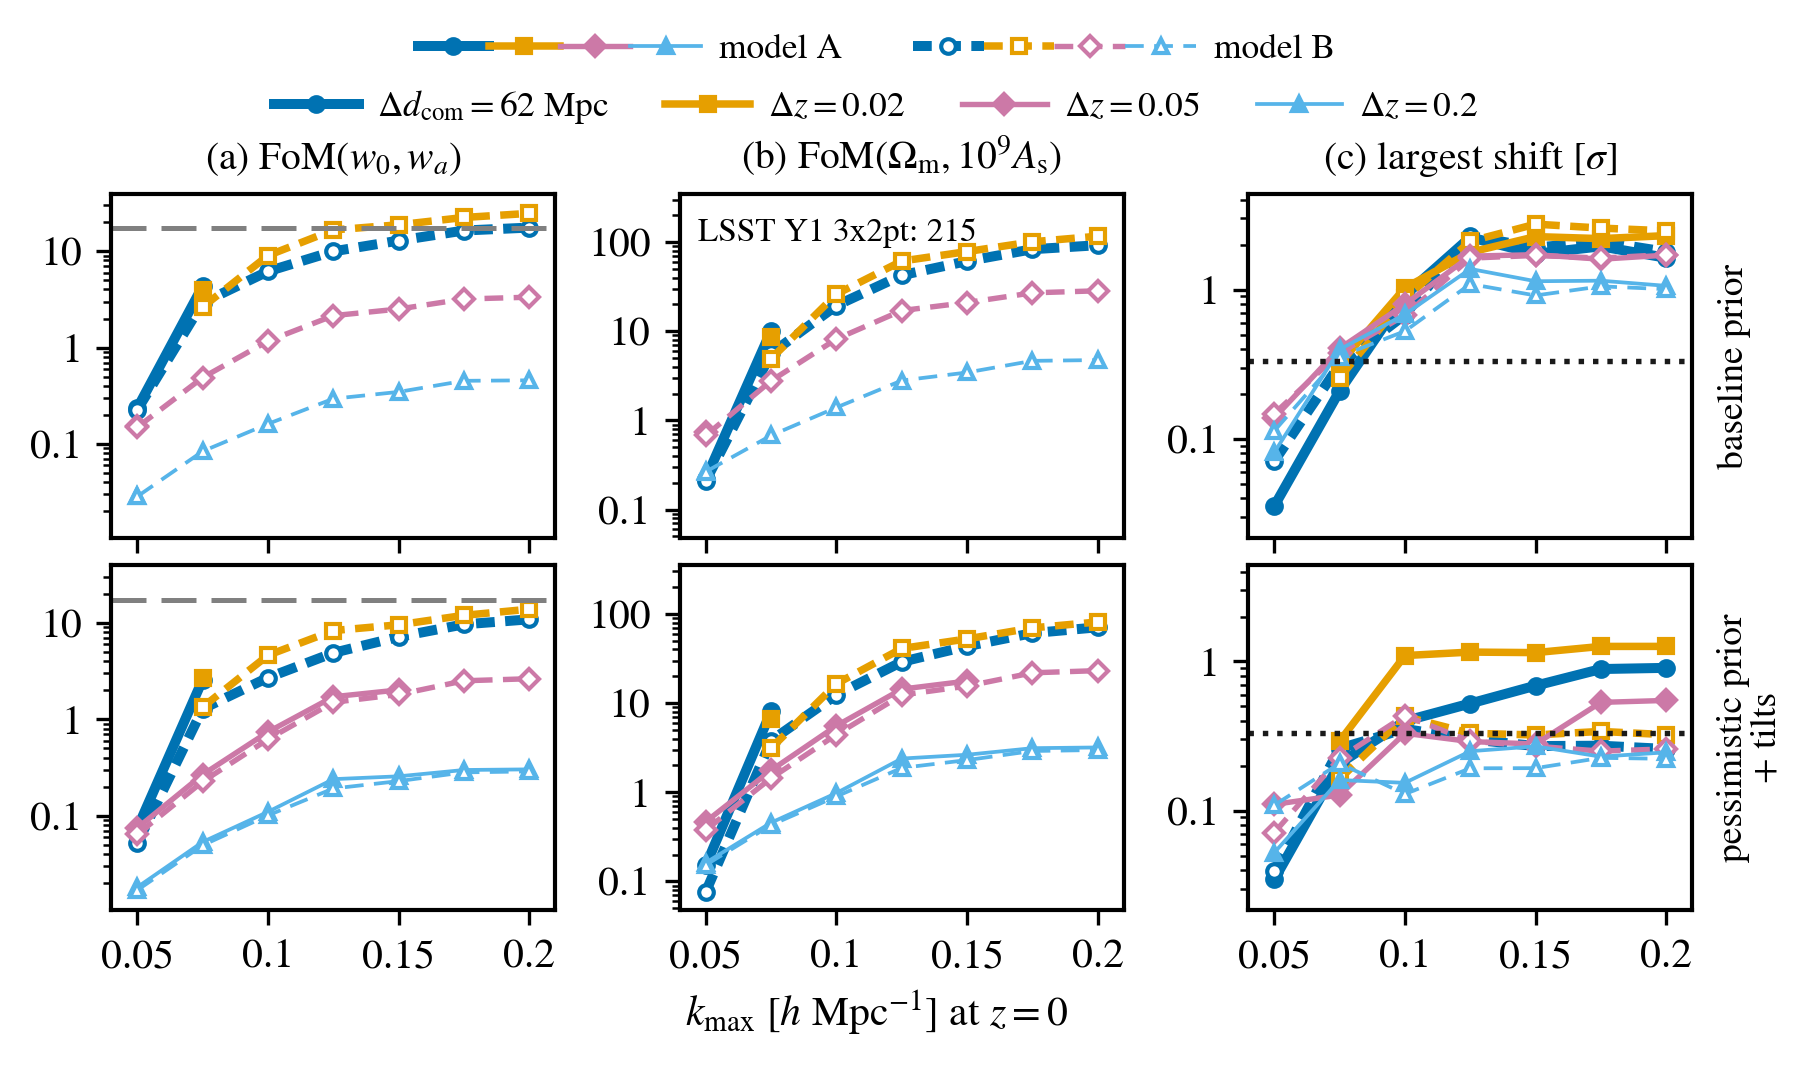

In [10]:
KMAX_LIST = [float(k) for k in KMAX_CUTS]


def per_cut(table, key, variant, prior, field=None):
    '''One entry per cut from a {(key, m, variant, prior): value} table (None: no fit).'''
    out = []
    for m in range(NK):
        entry = table[(key, m, variant, prior)]
        if entry is not None and field is not None:
            entry = entry[field]
        out.append(entry)
    return out


def layout_entry(key):
    '''The name, plotted label and color of one layout.'''
    return {'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key]}


def worst_per_cut(key, variant, prior):
    '''The largest shift over a variant's truths and scores, per cut (None: no fit).'''
    out = []
    for scores in per_cut(SCORES, key, variant, prior):
        out.append(None if scores is None else worst_score(scores)[0])
    return out


def break_entry(key, variant, prior):
    '''The break point of one variant and prior, with the truth that sets it.'''
    entry = BREAK[(key, variant, prior)]
    failure = None
    if entry['failure'] is not None:
        cut, value, family, score = entry['failure']
        failure = {'kmax': cut, 'value': value, 'truth': family, 'score': score}
    return {'kmax': entry['kmax'], 'passes_every_cut': entry['passes_every_cut'],
            'failure': failure}


fom_data = {
    'about': ('Two scenarios of DESI C_gg alone against the scale cut k_max [h/Mpc; the '
              'z = 0 value of a per-bin cut at k_max/D(zbar_i), D the growth factor, by '
              'the UV-fraction criterion, alpha = 0.05, within the shipped mask]: the '
              'baseline linear-bias prior with model A and model B (keys A, B), '
              'and the pessimistic prior with model A + tilts and model B + tilts '
              '(keys A tilts, B tilts; notes/higher_order_bias); the figure draws '
              'these two rows '
              'and labels the models model A and model B. fom = FoM(w0, wa) and '
              'fom_om_as = FoM(Omega_m, 10^9 A_s), each det(marginalized 2x2 '
              'covariance)^(-1/2), for every variant and prior (independent = free); '
              'null where a cut leaves no fit. shift: per cut, the shift of a fit of '
              'each variant to each truth, by Fisher linear response, (w0, wa) in units '
              'of the fit\'s ellipse, Omega_m and A_s in their own sigma; the truths '
              'are alpha_2 = +-12.5 h^-2 Mpc^2 (model A only), SN2 = +-5 units of '
              'f_sat sigma_sat^2/nbar, the b2 and bs2 offsets at +-1 sigma of the '
              'variant\'s widths, and the calibration drift, the offsets linear in '
              'redshift across each group with zero mean, changing by calibration_drift '
              '(the offsets to first order). worst: the largest of these shifts. '
              'break: the largest k_max with worst below shift_threshold there and at '
              'every smaller fitted cut, and the truth and score that fail first '
              '(kmax null: the smallest fitted cut fails). The model A FoMs beyond its '
              'break are kept: what extending model A would claim. LSST Y1 3x2pt '
              'references from the lsst_y1 project. Written by '
              'EXAMPLE_EVALUATE_FISHER_MODEL_B.ipynb.'),
    'kmax_h_per_Mpc': KMAX_LIST, 'shift_threshold': SHIFT_THRESHOLD,
    'scenarios': SCENARIOS, 'priors': FIT_PRIORS, 'prior_labels': PRIOR_LABELS,
    'variants': VARIANTS, 'params': ['w0wa', *SINGLE_PARAMS],
    'prior_widths': {model: {**FIXED_WIDTHS[model],
                             'counterterms': f'{COUNTERTERM_FRACTION}/k_max^2'}
                     for model in FIXED_WIDTHS},
    'truths': {'alpha2_h-2Mpc2': ALPHA2_TRUTH, 'SN2_units': SN2_TRUTH,
               'offsets': 'one sigma of the variant widths'},
    'calibration_drift': CAL_DRIFT,
    'lsst_y1_3x2pt_fom': LSST_Y1_SRD_FOM,
    'lsst_y1_3x2pt_fom_om_as': LSST_Y1_SRD_FOM_OM_AS,
    'layouts': [{**layout_entry(key),
                 'fom': {v: {p: per_cut(FOM, key, v, p, 'fom') for p in FIT_PRIORS}
                         for v in VARIANTS},
                 'fom_om_as': {v: {p: per_cut(FOM, key, v, p, 'fom_om_as')
                                   for p in FIT_PRIORS}
                               for v in VARIANTS},
                 'shift': {v: {p: per_cut(SCORES, key, v, p) for p in FIT_PRIORS}
                           for v in VARIANTS},
                 'worst': {v: {p: worst_per_cut(key, v, p) for p in FIT_PRIORS}
                           for v in VARIANTS},
                 'break': {v: {p: break_entry(key, v, p) for p in FIT_PRIORS}
                           for v in VARIANTS}}
                for key in LAYOUTS],
}

folder = NOTE_PLOTS + 'fom_kmax_models'
script = folder + '/plot_fom_kmax_models.py'
if not os.path.exists(script):
    raise RuntimeError(f'{script} is missing: the folder needs its plot script')
with open(folder + '/data.json', 'w') as f:
    json.dump(fom_data, f, indent=1)
# the standalone redraw: isolated mode, and a RuntimeWarning (a NaN in a
# reduction, say) stops the script
subprocess.run([sys.executable, '-I', '-W', 'error::RuntimeWarning', script], check=True)
display(Image(filename=folder + '/fom_kmax_models.png', width=760))

## 9. The summary model: model B + tilts on the pessimistic prior

The summary note, `notes/bias_model_summary`, quotes one configuration: model
B + tilts on the pessimistic linear-bias prior, at every cut. This section
collects what that one model gives, layout by layout and cut by cut, prints
it, and writes the data of three one-column figures of the summary note, each
into its own folder under `notes/bias_model_summary/plots/`:

- `summary_fom_kmax`: ${\rm FoM}(w_0, w_a)$ and ${\rm FoM}(\Omega_m, 10^9 A_s)$
  (section 6);
- `summary_shifts_kmax`: the largest shift of $(w_0, w_a)$, of $\Omega_m$ and of
  $A_s$ over the fixed truths. These are the truths of section 7 for model B
  ($\mathrm{SN}_2 = \pm5$, the offsets at $\pm1\sigma$ of model B's widths, and
  the calibration drift), plus $\alpha_2 = \pm12.5\,h^{-2}\,\mathrm{Mpc}^2$,
  which model B fits under its prior: the extra truth shows how far that prior
  pulls the fit;
- `summary_prior_draws`: the pessimistic-prior draws of the correlated-prior
  note's `prior_draws` figure (its bottom row), copied from that folder's
  `data.json`.

The cell also prints $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$ of
$(w_0, w_a)$, $\Omega_m$ and $A_s$ when every bin's linear bias follows its
group's known drift (the $r < 19.5$ flux limit in BGS, a conserved population
elsewhere, `bias_drift`) plus a residual drawn from the pessimistic prior, the
model A notebook's accuracy test; the summary note quotes its largest values
in a sentence, without a figure.

The statistic is the exact average over the truths and the data noise, as in
the model A notebook. With $A$ the fit's response per unit fractional
deviation $\delta_i$ of bin $i$'s linear bias ($b_2$ and $b_{s^2}$ follow $b_1$
through the calibrations), $\delta^0$ the known drift and $S$ the residual
covariance of the pessimistic prior,
$$\langle\chi^2_w\rangle = (A_w\delta^0)^\mathsf{T} C_w^{-1} (A_w\delta^0)
 + \mathrm{tr}\,[C_w^{-1}(A_w S A_w^\mathsf{T} + N_w)],$$
with $N_w$ the $(w_0, w_a)$ block of $F^{-1}F_0F^{-1}$, the share of the data
noise and of the Gaussian priors ($F_0$ the Fisher matrix without the
linear-bias precision), and $n_\mathrm{dof} = 2$; for $\Omega_m$ and $A_s$ the
same with the parameter's own row and $n_\mathrm{dof} = 1$. A value of 1 means
honest error bars. A check line compares model A's value at
$k_\mathrm{max} = 0.075$ with the model A notebook's (`goodness_of_fit`).

In [11]:
sys.path.insert(0, NOTE_PLOTS)
import make_theory_data as bias_theory

# the configuration of the summary note
SUMMARY_VARIANT, SUMMARY_PRIOR = 'B tilts', 'pessimistic'
# its figures go to the summary note, one folder each
SUMMARY_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/bias_model_summary/plots/'
# the known drift laws of the accuracy test: a conserved population in every
# group, replaced in BGS by the r < 19.5 flux limit
DRIFT_LAWS = ['conserved', 'flux_limit']


def bias_drift(key, law):
    '''The fractional deviation of every bin's b1 from B_g/D(z) under a known
    drift (as in the model A notebook); the higher-order biases follow b1.'''
    zbar = BIN_ZBAR[key]
    fiducial = fiducial_of(key)
    delta = np.zeros(len(zbar))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        if law == 'conserved':
            b_center = fiducial[leader]/bias_theory.growth(z.mean())[0]
            bias = bias_theory.conserved_bias(z, z.mean(), b_center)
        elif law == 'flux_limit' and name == 'BGS':
            bias = bias_theory.bgs_flux_limit_bias(z)
        else:
            continue
        delta[idx] = bias_theory.deviation_from_tied(z, bias)
    return delta


def known_drift(key):
    '''delta^0 of the accuracy test: the conserved population, with the BGS
    flux limit in the BGS group.'''
    delta = bias_drift(key, 'conserved')
    bgs = bias_groups(key)[0][2]
    delta[bgs] = bias_drift(key, 'flux_limit')[bgs]
    return delta


def honesty(system, delta0, S):
    '''sqrt(<chi2>/n_dof) of one fit under truths delta0 + residual ~ N(0, S).

    Returns:
      {'w0wa' or p: {'error_inflation', 'coverage', 'drift_only'}}: the
      statistic, the probability that the truth falls inside the fit's
      one-sigma region (for one parameter 2 Phi(1/s) - 1 is exact only
      without drift, so the coverage is quoted for (w0, wa) and the single
      parameters from the same Gaussian error), and the shift of the drift
      alone in sigma.
    '''
    key = system['key']
    M = COLUMNS[(key, system['variant'])][0]
    nbins = len(BIN_ZBAR[key])
    beta = np.array([fiducial_of(key)[x] for x in derivs[key]['leaders']])
    A_w, A_p = responses(system, M[:, -nbins:]*beta[None, :])
    noise = system['F_inv'] @ system['F0'] @ system['F_inv']
    Ci, iw = system['Ci'], system['iw']
    d_w = A_w @ delta0
    K_w = np.outer(d_w, d_w) + A_w @ S @ A_w.T + noise[np.ix_(iw, iw)]
    out = {'w0wa': {'error_inflation': float(np.sqrt(np.trace(Ci @ K_w)/2.0)),
                    'coverage': coverage_2d(Ci, K_w),
                    'drift_only': float(np.sqrt(d_w @ Ci @ d_w))}}
    for p, i in system['ip'].items():
        a = A_p[p]
        drift_p = float(a @ delta0)
        # the scatter about the drift, in units of the parameter's sigma
        spread = float(a @ S @ a + noise[i, i]/system['sigma'][p]**2)
        # the probability that |drift + scatter| < 1 sigma for a Gaussian
        # error of mean drift_p and variance spread
        r = np.sqrt(2.0*spread)
        coverage = 0.5*(scipy.special.erf((1.0 - drift_p)/r)
                        + scipy.special.erf((1.0 + drift_p)/r))
        out[p] = {'error_inflation': float(np.sqrt(drift_p**2 + spread)),
                  'coverage': float(coverage), 'drift_only': abs(drift_p)}
    return out


S_PESS = {key: residual_covariance(key, BIAS_ASSUMPTIONS['pessimistic']) for key in LAYOUTS}
DELTA0 = {key: known_drift(key) for key in LAYOUTS}

# the check against the model A notebook: its accuracy test at its cut
with open(NOTE_PLOTS + 'goodness_of_fit/data.json') as f:
    gof_a = json.load(f)
m_a = int(np.argmin(np.abs(KMAX_CUTS - gof_a['kmax_h_per_Mpc'])))
worst_check = 0.0
for lay in gof_a['layouts']:
    for variant in MODEL_A_VARIANTS:
        for prior in BIAS_ASSUMPTIONS:
            system, status = fit_system(lay['name'], m_a, variant, prior)
            ours = honesty(system, DELTA0[lay['name']], S_PESS[lay['name']])
            for score, value in lay['gof'][variant]['pessimistic'][prior].items():
                worst_check = max(worst_check,
                                  abs(ours[score]['error_inflation']/value - 1.0))
print(f'check against the model A notebook at k_max = {KMAX_CUTS[m_a]:g}: '
      f'max |sqrt(<chi2>/n_dof)/model A notebook - 1| = {worst_check:.1e}')

# the summary model at every cut: FoMs, shifts and the statistic
SUMMARY = {}
for key in LAYOUTS:
    truths = dict(variant_truths(key, SUMMARY_VARIANT))
    a2 = block_vector(key, {'a2': ALPHA2_TRUTH})
    truths['alpha2 +'], truths['alpha2 -'] = a2, -a2
    for m in range(NK):
        system, status = fit_system(key, m, SUMMARY_VARIANT, SUMMARY_PRIOR)
        if system is None:
            SUMMARY[(key, m)] = None
            continue
        SUMMARY[(key, m)] = {'fom': system['fom'], 'fom_om_as': system['fom_om_as'],
                             'shift': truth_scores(system, truths),
                             'honesty': honesty(system, DELTA0[key], S_PESS[key])}

SCORED = ['w0wa', *SINGLE_PARAMS]


def summary_rows(reduce):
    '''One row per layout and score, one column per cut (NaN: no fit).'''
    rows = {}
    for key in LAYOUTS:
        for score in SCORED:
            rows[(key, score)] = {float(k): (np.nan if SUMMARY[(key, m)] is None
                                             else reduce(SUMMARY[(key, m)], score))
                                  for m, k in enumerate(KMAX_CUTS)}
    return pd.DataFrame(rows).T


def largest(entry, score):
    return max(v[score] for v in entry['shift'].values())


def largest_truth(entry, score):
    '''The truth family that sets the largest shift of one score.'''
    best = max(entry['shift'], key=lambda t: entry['shift'][t][score])
    return truth_family(best)


print('model B + tilts on the pessimistic prior: largest shift [sigma] over the '
      'truths (alpha_2, SN2, offsets, calibration drift); columns: k_max')
display(summary_rows(largest))
print('the truth family that sets it')
display(summary_rows(largest_truth))
print('model B + tilts on the pessimistic prior, truths = known drifts + pessimistic '
      'scatter: sqrt(<chi2>/n_dof) (1 = honest error bars); columns: k_max')
display(summary_rows(lambda e, s: e['honesty'][s]['error_inflation']))
print('the same truths: coverage of the 68.3% region')
display(summary_rows(lambda e, s: e['honesty'][s]['coverage']))
print('the same truths: the shift of the drift alone [sigma]')
display(summary_rows(lambda e, s: e['honesty'][s]['drift_only']))

check against the model A notebook at k_max = 0.075: max |sqrt(<chi2>/n_dof)/model A notebook - 1| = 7.5e-10
model B + tilts on the pessimistic prior: largest shift [sigma] over the truths (alpha_2, SN2, offsets, calibration drift); columns: k_max


0.05    0.075   0.1    0.125   0.15    0.175   0.2  
Delta d_com = 62 Mpc w0wa   0.006969  0.2095  0.2304 0.2207  0.2167  0.3076  0.3943
                     omegam  0.02068  0.2609   0.353 0.2737  0.2489  0.2136  0.1919
                     As_1e9  0.03934 0.06506  0.1556  0.301  0.2709  0.3212  0.4403
Delta z = 0.02       w0wa        NaN  0.1342  0.2506 0.2805  0.2767  0.3632  0.4824
                     omegam      NaN  0.1631  0.4278 0.2296  0.2359  0.2153   0.186
                     As_1e9      NaN  0.1106  0.2474 0.3301  0.3217  0.3585  0.4975
Delta z = 0.05       w0wa    0.07133  0.1336  0.3582 0.2165  0.2023  0.2399  0.2836
                     omegam  0.04329  0.2254  0.4334  0.235  0.2132  0.2135  0.2526
                     As_1e9  0.01749  0.1127  0.2524  0.292  0.2704  0.3263  0.3918
Delta z = 0.2        w0wa    0.09712  0.1871 0.05317 0.1715  0.0317 0.09534  0.1035
                     omegam   0.1089  0.2075 0.08185 0.0814 0.05468 0.02044 0.02126
                     As_1e9  0.08104  0.1347  0.1292 0.1923  0.1927  0.2259  0.2226

the truth family that sets it


0.05     0.075    0.1      0.125    0.15     0.175    0.2  
Delta d_com = 62 Mpc w0wa        SN2  offsets  offsets  offsets   alpha2   alpha2   alpha2
                     omegam   alpha2  offsets  offsets  offsets  offsets  offsets  offsets
                     As_1e9  offsets   alpha2      SN2  offsets  offsets   alpha2   alpha2
Delta z = 0.02       w0wa        NaN      SN2      SN2  offsets  offsets   alpha2   alpha2
                     omegam      NaN  offsets  offsets  offsets  offsets  offsets   alpha2
                     As_1e9      NaN  offsets  offsets  offsets  offsets   alpha2   alpha2
Delta z = 0.05       w0wa    offsets  offsets  offsets  offsets  offsets   alpha2   alpha2
                     omegam  offsets  offsets  offsets  offsets  offsets   alpha2   alpha2
                     As_1e9  offsets  offsets  offsets  offsets  offsets   alpha2   alpha2
Delta z = 0.2        w0wa    offsets  offsets  offsets  offsets  offsets  offsets  offsets
                     omegam  offsets  offsets  offsets  offsets  offsets      SN2      SN2
                     As_1e9  offsets  offsets  offsets  offsets  offsets  offsets  offsets

model B + tilts on the pessimistic prior, truths = known drifts + pessimistic scatter: sqrt(<chi2>/n_dof) (1 = honest error bars); columns: k_max


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc w0wa        1      1      1  1.001  1.001  1.011  1.003
                     omegam      1      1      1  1.002      1  1.015  1.004
                     As_1e9      1      1      1  1.001      1      1      1
Delta z = 0.02       w0wa      NaN      1      1  1.001  1.001  1.006  1.006
                     omegam    NaN      1      1      1      1  1.009   1.01
                     As_1e9    NaN      1      1  1.001  1.001      1      1
Delta z = 0.05       w0wa        1      1  1.003  1.009  1.004  1.013  1.011
                     omegam      1      1  1.006   1.02  1.007  1.023   1.02
                     As_1e9      1      1  1.001  1.003  1.003  1.002  1.002
Delta z = 0.2        w0wa        1      1      1      1      1      1      1
                     omegam      1      1      1      1      1      1      1
                     As_1e9      1      1      1      1      1      1      1

the same truths: coverage of the 68.3% region


0.05   0.075  0.1    0.125  0.15   0.175  0.2  
Delta d_com = 62 Mpc w0wa   0.6827 0.6827 0.6827 0.6817 0.6821 0.6746 0.6808
                     omegam 0.6827 0.6827 0.6826 0.6819 0.6827 0.6753 0.6809
                     As_1e9 0.6827 0.6827 0.6827 0.6822 0.6825 0.6827 0.6826
Delta z = 0.02       w0wa      NaN 0.6827 0.6826 0.6821 0.6822  0.678 0.6784
                     omegam    NaN 0.6826 0.6825 0.6825 0.6826 0.6785 0.6779
                     As_1e9    NaN 0.6827 0.6827 0.6821 0.6823 0.6826 0.6827
Delta z = 0.05       w0wa   0.6826 0.6825 0.6803  0.676 0.6799 0.6737 0.6745
                     omegam 0.6825 0.6825 0.6797  0.673 0.6792 0.6714 0.6727
                     As_1e9 0.6825 0.6826 0.6821 0.6813 0.6811 0.6817 0.6818
Delta z = 0.2        w0wa   0.6827 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827
                     omegam 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827
                     As_1e9 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827 0.6827

the same truths: the shift of the drift alone [sigma]


0.05      0.075     0.1       0.125     0.15      0.175     0.2  
Delta d_com = 62 Mpc w0wa     0.01318  0.008478   0.01174   0.07477   0.05601    0.2124    0.1026
                     omegam   0.01089  0.009018   0.02113   0.05863  0.001897    0.1754    0.0857
                     As_1e9   0.01077 0.0002837  0.009207    0.0454   0.02432  0.009924   0.01783
Delta z = 0.02       w0wa         NaN  0.005232    0.0238   0.05632   0.05266    0.1612    0.1531
                     omegam       NaN   0.01814   0.03091   0.02804   0.01919    0.1315    0.1411
                     As_1e9       NaN  0.001898   0.00441   0.05123   0.04051   0.02017 0.0006417
Delta z = 0.05       w0wa     0.01508   0.03054    0.1157    0.1935    0.1237    0.2244    0.2142
                     omegam   0.02972   0.02952    0.1105    0.2012    0.1205    0.2168    0.2035
                     As_1e9   0.02796   0.01688   0.04995   0.07511   0.08227    0.0644   0.05951
Delta z = 0.2        w0wa   3.039e-12 5.186e-12 3.208e-12 6.114e-12 2.886e-12 4.224e-12 2.078e-12
                     omegam 2.784e-12 5.499e-12 1.294e-12 6.072e-12 7.986e-13 9.573e-13 8.067e-13
                     As_1e9 1.506e-12 2.446e-12 3.349e-13  5.97e-12 2.107e-12 1.496e-12 8.131e-13

**What the summary model shows.**

- Its error bars are honest at every cut, on every layout:
  $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$ is at most $1.023$ ($\Omega_m$ on
  $\Delta z = 0.05$ at $0.175$), the coverage of the $1\sigma$ region at least
  $67.1\%$ against $68.3\%$, and the known drift alone moves no score by more
  than $0.22\sigma$. On $\Delta z = 0.2$ the free amplitude and tilt of every
  group absorb the drift exactly, and the statistic is $1$.
- Its largest shift over the fixed truths stays below $\sigma/3$ at $0.05$ and
  $0.075$ on every layout, and on $\Delta z = 0.2$ at every cut (at most
  $0.23\sigma$). At $0.1$ the offsets move $\Omega_m$ by $0.35\sigma$
  ($\Delta d_\mathrm{com} = 62$ Mpc) and $0.43\sigma$ ($\Delta z = 0.02$ and
  $0.05$); at $0.125$ and $0.15$ the largest shift is $0.27$–$0.33\sigma$ on the
  three thinner layouts; at $0.175$ it is $0.32$–$0.36\sigma$.
- At $0.175$ and $0.2$, $\alpha_2 = \pm12.5\,h^{-2}\,\mathrm{Mpc}^2$, which model
  B fits under a prior of width $0.5/k_\mathrm{max}^2$ ($16.3$ and $12.5$ there),
  sets the largest shift of $(w_0, w_a)$ and $A_s$ on the three thinner layouts:
  at $0.2$ it is $0.44\sigma$ ($\Delta d_\mathrm{com} = 62$ Mpc), $0.50\sigma$
  ($\Delta z = 0.02$) and $0.39\sigma$ ($\Delta z = 0.05$), against $0.26$,
  $0.32$ and $0.26\sigma$ for the truths of section 7 alone.
- ${\rm FoM}(w_0, w_a) = 1.29$, $1.34$, $0.227$ and $0.0495$ at $0.075$, and
  $10.9$, $13.9$, $2.64$ and $0.289$ at $0.2$ ($\Delta d_\mathrm{com} = 62$ Mpc,
  $\Delta z = 0.02$, $0.05$, $0.2$); ${\rm FoM}(\Omega_m, 10^9 A_s) = 70.8$,
  $81.3$, $23.1$ and $2.98$ at $0.2$. Both stay below the LSST Y1 3x2pt values,
  $17.26$ and $214.9$.

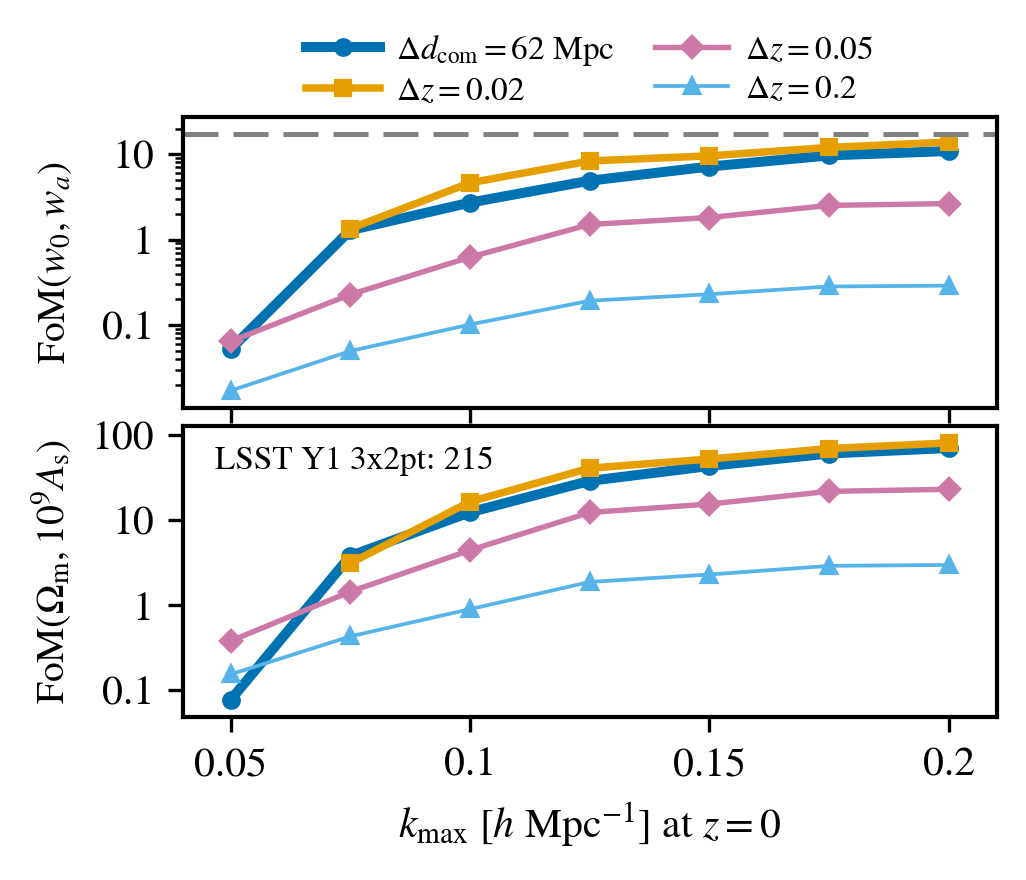

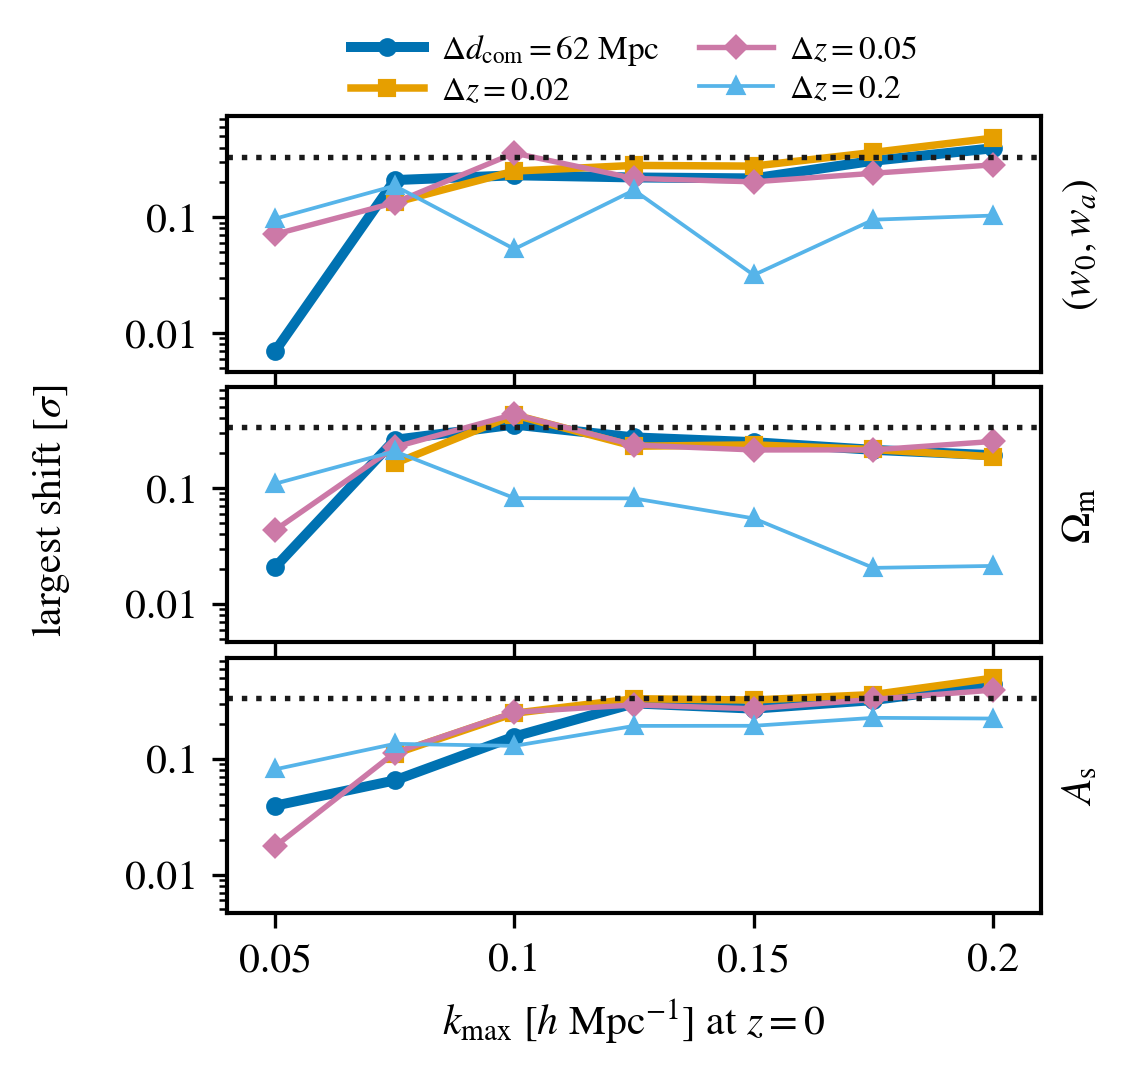

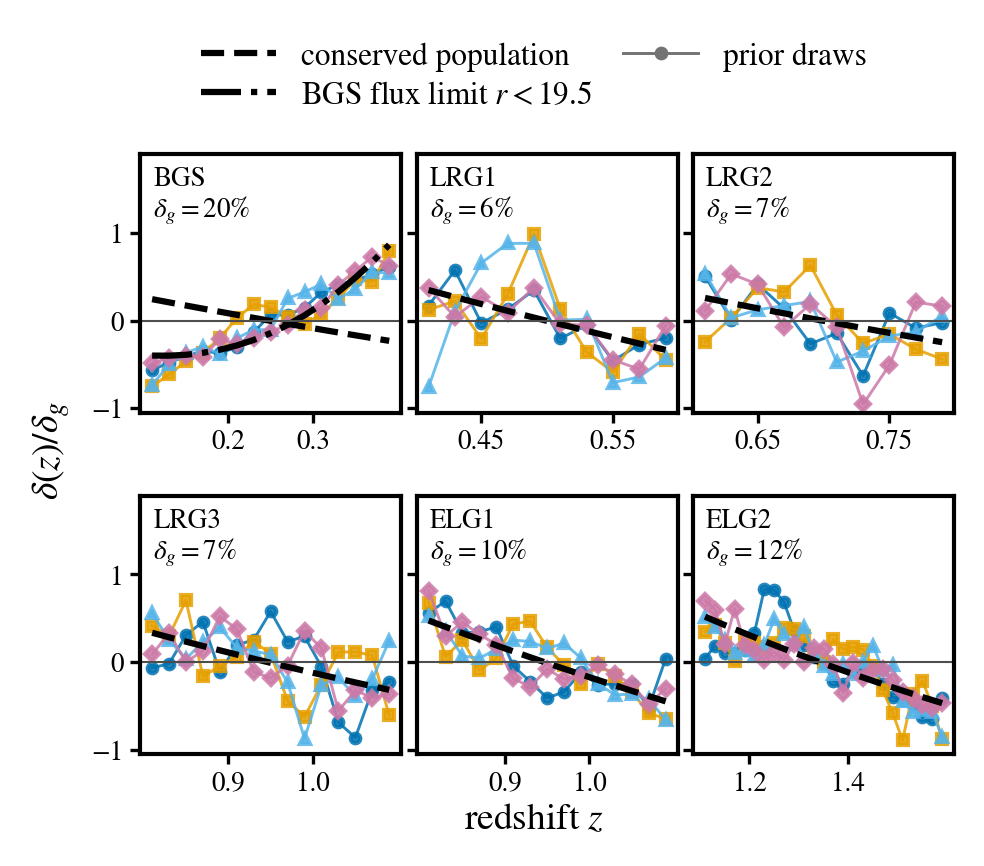

In [12]:
def summary_layouts(per_cut):
    '''The layout list of a summary data.json: name, label, color and the
    entries per_cut(key) adds.'''
    return [{**layout_entry(key), **per_cut(key)} for key in LAYOUTS]


def by_cut(key, get):
    '''One entry per cut (None: no fit).'''
    return [None if SUMMARY[(key, m)] is None else get(SUMMARY[(key, m)])
            for m in range(NK)]


SUMMARY_ABOUT = ('model B + tilts (notes/higher_order_bias: offsets and counterterms '
                 'per group with a straight line in redshift, flat priors on the tilts, '
                 'SN0 and SN2 per group) on the pessimistic linear-bias prior, DESI '
                 'C_gg alone, against the scale cut k_max [h/Mpc; the z = 0 value of a '
                 'per-bin cut at k_max/D(zbar_i), D the growth factor, by the UV-fraction '
                 'criterion, alpha = 0.05, within the shipped mask]; null where a cut '
                 'leaves no fit. Written by EXAMPLE_EVALUATE_FISHER_MODEL_B.ipynb.')
summary_common = {'kmax_h_per_Mpc': KMAX_LIST, 'variant': SUMMARY_VARIANT,
                  'prior': SUMMARY_PRIOR,
                  'prior_widths': {**FIXED_WIDTHS['B'],
                                   'counterterms': f'{COUNTERTERM_FRACTION}/k_max^2'}}
summary_exports = {
    'summary_fom_kmax': {
        'about': 'FoM(w0, wa) (fom) and FoM(Omega_m, 10^9 A_s) (fom_om_as), each '
                 'det(marginalized 2x2 covariance)^(-1/2), of ' + SUMMARY_ABOUT
                 + ' LSST Y1 3x2pt references from the lsst_y1 project.',
        **summary_common, 'lsst_y1_3x2pt_fom': LSST_Y1_SRD_FOM,
        'lsst_y1_3x2pt_fom_om_as': LSST_Y1_SRD_FOM_OM_AS,
        'layouts': summary_layouts(lambda key: {
            'fom': by_cut(key, lambda e: e['fom']),
            'fom_om_as': by_cut(key, lambda e: e['fom_om_as'])})},
    'summary_shifts_kmax': {
        'about': 'The shifts of ' + SUMMARY_ABOUT + ' Truths, each the same in every '
                 'bin (the drift: linear across each group): alpha_2 = +-12.5 h^-2 '
                 'Mpc^2 (fitted by model B under its prior), SN2 = +-5 units of f_sat '
                 'sigma_sat^2/nbar, the b2 and bs2 offsets at +-1 sigma of model B\'s '
                 'widths (+-(2, 1), to first order), and the calibration drift (the '
                 'offsets linear in redshift across each group with zero mean, '
                 'changing by calibration_drift; absorbed by the tilts). shift: per '
                 'cut and truth, (w0, wa) in units of the fit\'s ellipse, Omega_m and '
                 'A_s in their own sigma, by Fisher linear response; largest: the '
                 'largest over the truths, per score.',
        **summary_common, 'shift_threshold': SHIFT_THRESHOLD, 'params': SCORED,
        'calibration_drift': CAL_DRIFT,
        'truths': {'alpha2_h-2Mpc2': ALPHA2_TRUTH, 'SN2_units': SN2_TRUTH,
                   'offsets': 'one sigma of the model B widths'},
        'layouts': summary_layouts(lambda key: {
            'largest': {s: by_cut(key, lambda e, s=s: largest(e, s)) for s in SCORED},
            'shift': by_cut(key, lambda e: e['shift'])})},
}
# the pessimistic-prior draws of the correlated-prior note's prior_draws figure
with open(NOTE_PLOTS + 'prior_draws/data.json') as f:
    draws_v2 = json.load(f)
summary_exports['summary_prior_draws'] = {
    'about': ('The pessimistic-prior row of notes/correlated_bias_prior_v2/plots/'
              'prior_draws/data.json, copied by EXAMPLE_EVALUATE_FISHER_MODEL_B.ipynb. '
              'Its about: ' + draws_v2['about']),
    'prior': draws_v2['priors']['pessimistic'],
    **{k: draws_v2[k] for k in draws_v2 if k not in ('about', 'priors', 'groups')},
    'groups': [{**{k: v for k, v in group.items() if k not in ('draws', 'neighbor_rms_prior')},
                'draws': group['draws']['pessimistic'],
                **({'neighbor_rms_prior': group['neighbor_rms_prior']['pessimistic']}
                   if isinstance(group.get('neighbor_rms_prior'), dict) else {})}
               for group in draws_v2['groups']],
}

for name, data in summary_exports.items():
    folder = SUMMARY_PLOTS + name
    script = folder + f'/plot_{name}.py'
    if not os.path.exists(script):
        raise RuntimeError(f'{script} is missing: the folder needs its plot script')
    with open(folder + '/data.json', 'w') as f:
        json.dump(data, f, indent=1)
    subprocess.run([sys.executable, '-I', '-W', 'error::RuntimeWarning', script], check=True)
    display(Image(filename=f'{folder}/{name}.png', width=420))

## 10. Conclusion

The printed tables and the figures hold four results:

1. **Where each model breaks** (section 7, column (c) of the figure). In the
   baseline scenario both models break at $0.075$ on
   $\Delta d_\mathrm{com} = 62$ Mpc and $\Delta z = 0.02$ and at $0.05$ on
   $\Delta z = 0.05$ and $0.2$, on the calibration drift except for model A on
   $\Delta z = 0.02$ ($\alpha_2$). In the pessimistic scenario model A + tilts
   breaks at $0.075$ on the two thin layouts and at $0.15$ on $\Delta z = 0.05$
   (on $\alpha_2$), model B + tilts at $0.075$ on those three layouts (on the
   offsets), and both pass every cut up to $0.2$ on $\Delta z = 0.2$.
2. **The FoMs of models A and B** (section 6, columns (a) and (b)). At every
   cut the baseline scenario gives the larger FoMs and, from $0.125$ on, the
   larger shifts (up to $2.75\sigma$, against $1.26\sigma$ for model A and
   $0.43\sigma$ for model B + tilts in the pessimistic scenario). Model B
   reaches ${\rm FoM}(w_0, w_a) = 17.5$, $24.6$, $3.33$ and $0.458$ at $0.2$ in
   the baseline scenario, and model B + tilts $10.9$, $13.9$, $2.64$ and $0.289$
   in the pessimistic one ($\Delta d_\mathrm{com} = 62$ Mpc, $\Delta z = 0.02$,
   $0.05$, $0.2$).
3. **The correlated-prior note's figure**:
   `notes/correlated_bias_prior_v2/plots/fom_kmax_models/`, two rows (the
   scenarios) by three columns, whose `data.json` holds every FoM, shift and
   break point it draws, the per-truth shifts, the free prior, and the model A
   FoMs beyond the break.
4. **The summary model** (section 9): model B + tilts on the pessimistic prior
   keeps honest error bars at every cut ($\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}
   \leq 1.023$); its largest fixed-truth shift reaches $0.43\sigma$ at $0.1$
   (the offsets) and $0.50\sigma$ at $0.2$ ($\alpha_2$ at its prior width). The
   three figures of `notes/bias_model_summary/plots/` hold its FoMs, shifts and
   prior draws.

The random truths of section 7 test the error bars of model A when $\alpha_2$
scatters over model B's prior, which the break point does not
test: a fit can stay below $\sigma/3$ for every fixed truth while its error bars
are too small for the scatter of the truths. The prior-mismatch table of section
7 shows what model A's tighter offset priors cost when the calibrations scatter
as widely as model B allows.

The absolute FoMs depend on the covariance: Gaussian, computed at the model A
fiducial with its one-loop spectra, and the same for both models; the
comparisons between models, variants and priors hold it fixed.
Model B has no redshift-space one-loop terms here.

All $k_\mathrm{max}$ above are quoted at $z = 0$; each bin is cut by the
UV-fraction criterion at $k_\mathrm{max}/D(\bar z_i)$ ($\alpha = 0.05$) within the
shipped mask.